# NYC Yellow Taxi · Calidad de datos y depuración
## Análisis comparativo, persistencia Parquet y reutilización con Apache Spark

Este notebook extiende el análisis distribuido de los viajes de taxi amarillo de Nueva York realizado en la implementación de referencia.

El objetivo no es modificar retrospectivamente el dataset original del proyecto, sino construir una **capa analítica de calidad de datos** que permita:

- identificar observaciones claramente anómalas;
- definir criterios explícitos y reproducibles de depuración;
- cuantificar cuántos registros elimina cada criterio;
- analizar la coincidencia entre criterios;
- comparar las distribuciones antes y después de la depuración;
- evaluar el impacto sobre medias, medianas y percentiles;
- comprobar la estabilidad de los patrones temporales y territoriales;
- persistir el dataset depurado en un formato analítico reutilizable;
- verificar su integridad y reproducibilidad después de la persistencia.

La versión de referencia conserva todos los registros que superan los filtros estructurales iniciales. Este notebook parte del mismo pipeline y añade posteriormente una segunda fase de **validación de depuración**.

La depuración no se realizará mediante eliminación arbitraria de percentiles. Los umbrales se evaluarán explícitamente y se documentará su impacto antes de construir el dataset analítico depurado.

## 1. Configuración inicial y entorno

### 1.1. Librerías y estructura del proyecto

El proyecto utiliza una estructura portable en la que los datasets se almacenan en `data/` y las funciones auxiliares en `src/`.

Las rutas se resuelven de forma relativa al proyecto para evitar dependencias de directorios personales y facilitar la reproducción del análisis en otros sistemas.

In [1]:
# ============================================================
# LIBRERÍAS
# ============================================================
from pathlib import Path
from time import perf_counter

import io
import os
import sys

import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns

from pyspark.sql import functions as F

from pyspark.sql.types import (
    StructType,
    StructField,
    IntegerType,
    DoubleType,
    StringType,
    TimestampType
)

from sedona.spark import SedonaContext

from contextlib import contextmanager, redirect_stdout


# ============================================================
# LOCALIZACIÓN DEL PROYECTO
# ============================================================
start_dir = Path.cwd().resolve()

project_dir = next(
    (
        path for path in [start_dir, *start_dir.parents]
        if (path / 'data').is_dir() and (path / 'src').is_dir()
    ),
    None
)

if project_dir is None:
    raise FileNotFoundError(
        'No se ha podido localizar la raíz del proyecto. '
        'Deben existir las carpetas "data" y "src".'
    )


# ============================================================
# DIRECTORIOS BASE
# ============================================================
data_dir = project_dir / 'data'
src_dir = project_dir / 'src'


# ============================================================
# DIRECTORIOS DE SALIDA
# ============================================================
images_dir = project_dir / 'images' / 'depurado_local'

outputs_dir = project_dir / 'outputs' / 'depurado_local'

tables_dir = outputs_dir / 'tables'

images_dir.mkdir(parents=True, exist_ok=True)
outputs_dir.mkdir(parents=True, exist_ok=True)
tables_dir.mkdir(parents=True, exist_ok=True)


# ============================================================
# FUNCIONES AUXILIARES
# ============================================================
if str(src_dir) not in sys.path:
    sys.path.insert(0, str(src_dir))

from aux_func import (
    DAYS_ORDER,
    DAY_LABELS,
    DISTRICT_LABELS,
    DISTRICTS_REFERENCE,
    compute_comparison_stats,
    get_percentile_profile,
    relative_change,
    save_figure,
    save_table
)


# ============================================================
# RECURSOS PRINCIPALES
# ============================================================
taxi_csv_path = data_dir / 'yellow_tripdata_2015-01.csv'

geojson_path = data_dir / 'NYC_Community_Districts.geojson'

print('Estructura del proyecto localizada correctamente.')

Estructura del proyecto localizada correctamente.


### 1.2. Sesión local de Apache Spark y Apache Sedona

La ejecución principal utiliza una sesión local de Apache Spark con todos los núcleos disponibles mediante `local[*]`.

Apache Sedona amplía Spark con operaciones espaciales distribuidas. La sesión incorpora el paquete `sedona-spark-shaded` compatible con Spark 4.1 y configura la zona horaria en UTC para garantizar un tratamiento consistente de las variables temporales.

Los mensajes internos de inicialización de Spark, resolución de dependencias y componentes opcionales de Sedona se omiten, ya que no forman parte de los resultados del análisis. Las dependencias y particularidades del entorno se documentan en el README del repositorio.

In [2]:
# ============================================================
# SESIÓN LOCAL DE SPARK + APACHE SEDONA
# ============================================================
# Supresión de mensajes de arranque
@contextmanager
def suppress_native_output():
    """
    Oculta stdout/stderr generado por Java/Spark durante el arranque.
    """
    stdout_fd = os.dup(1)
    stderr_fd = os.dup(2)

    try:
        with open(os.devnull, "w") as devnull:
            os.dup2(devnull.fileno(), 1)
            os.dup2(devnull.fileno(), 2)
            yield
    finally:
        os.dup2(stdout_fd, 1)
        os.dup2(stderr_fd, 2)
        os.close(stdout_fd)
        os.close(stderr_fd)


# Evita el warning de resolución del hostname en WSL
os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"


# CREACIÓN DE LA SESIÓN
with suppress_native_output():

    spark = (
        SedonaContext.builder()
        .master("local[*]")
        .appName("NYC_Taxi_Spark_Analytics")
        .config(
            "spark.jars.packages",
            "org.apache.sedona:sedona-spark-shaded-4.1_2.13:1.9.0",
        )
        .config("spark.sql.session.timeZone", "UTC")
        .config("spark.driver.memory", "4g")
        .config("spark.sql.shuffle.partitions", "8")
        .config("spark.ui.showConsoleProgress", "false")
        .getOrCreate()
    )

    # Importante: ANTES de inicializar Sedona
    spark.sparkContext.setLogLevel("ERROR")

    sedona = SedonaContext.create(spark)

print(f"Spark {spark.version} + Apache Sedona inicializados correctamente.")

Spark 4.1.0 + Apache Sedona inicializados correctamente.


In [3]:
# ============================================================
# COMPROBACIÓN DEL ENTORNO
# ============================================================
environment_summary_pd = pd.DataFrame({
    'Componente': [
        'Apache Spark',
        'Apache Sedona',
        'Master',
        'Zona horaria',
        'Shuffle partitions'
    ],
    'Configuración': [
        spark.version,
        '1.9.0',
        spark.sparkContext.master,
        spark.conf.get('spark.sql.session.timeZone'),
        spark.conf.get('spark.sql.shuffle.partitions')
    ]
}).set_index('Componente')

environment_summary_pd

,Configuración
Componente,
Apache Spark,4.1.0
Apache Sedona,1.9.0
Master,local[*]
Zona horaria,UTC
Shuffle partitions,8


## 2. Dataset y preparación distribuida
El análisis utiliza los registros de **enero de 2015** contenidos en `yellow_tripdata_2015-01.csv`.

### 2.1. Datos de viajes

El análisis parte de registros de viajes realizados por taxis amarillos de Nueva York. Cada registro contiene información temporal, geográfica y económica del trayecto, incluyendo las coordenadas de origen y destino, distancia recorrida, número de pasajeros, tarifa, propina y forma de pago.

A continuación se realiza la carga mediante Spark y se aplica una secuencia distribuida de transformaciones destinada a eliminar registros inconsistentes y generar nuevas variables útiles para el análisis.

#### Variables principales

El dataset contiene información temporal, geográfica y económica de cada trayecto. Las variables utilizadas a lo largo del análisis se describen a continuación.

| Campo                   | Descripción                                                                                                                               |
|-------------------------|-------------------------------------------------------------------------------------------------------------------------------------------|
| `VendorID`              | Código que identifica al proveedor TPEP que suministró el registro (1 = Creative Mobile Technologies; 2 = VeriFone Inc.)                  |
| `tpep_pickup_datetime`  | Fecha y hora en que se activó el taxímetro.                                                                                               |
| `tpep_dropoff_datetime` | Fecha y hora en que se desactivó el taxímetro.                                                                                            |
| `passenger_count`       | Número de pasajeros en el vehículo (valor ingresado por el conductor).                                                                    |
| `trip_distance`         | Distancia recorrida en millas reportada por el taxímetro.                                                                                 |
| `pickup_longitude`      | Longitud del lugar donde se activó el taxímetro.                                                                                          |
| `pickup_latitude`       | Latitud del lugar donde se activó el taxímetro.                                                                                           |
| `RateCodeID`            | Código de tarifa vigente al final del viaje (1=Standard rate, 2=JFK, 3=Newark, 4=Nassau or Westchester, 5=Negotiated fare, 6=Group ride). |
| `store_and_fwd_flag`    | Indica si el registro se almacenó en memoria del vehículo antes de enviarlo (Y = store and forward; N = not a store and forward trip).    |
| `dropoff_longitude`     | Longitud del lugar donde se desactivó el taxímetro.                                                                                       |
| `dropoff_latitude`      | Latitud del lugar donde se desactivó el taxímetro.                                                                                        |
| `payment_type`          | Código numérico del método de pago (1=Credit card, 2=Cash, 3=No charge, 4=Dispute, 5=Unknown, 6=Voided trip).                             |
| `fare_amount`           | Tarifa calculada por tiempo y distancia según el taxímetro.                                                                               |
| `extra`                 | Cargos y recargos varios (p. ej., recargos por hora punta, nocturnos).                                                                    |
| `mta_tax`               | Impuesto MTA de 0.50 aplicado automáticamente según la tarifa.                                                                            |
| `improvement_surcharge`  | Recargo de mejora de 0.30 aplicado al inicio del viaje (vigente desde 2015).                                                              |
| `tip_amount`            | Propina registrada automáticamente para pagos con tarjeta; no incluye las propinas en efectivo.                                           |
| `tolls_amount`          | Total de peajes pagados en el viaje.                                                                                                      |
| `total_amount`          | Precio total cobrado al pasajero (no incluye propinas en efectivo).                                                                       |

#### Esquema explícito de lectura

El dataset se distribuye en formato CSV, por lo que los tipos de las columnas no forman parte del propio formato de almacenamiento.

Como la estructura de los datos es conocida, se define explícitamente un esquema mediante `StructType` y `StructField` en lugar de depender de `inferSchema`.

Esto fija el contrato de entrada del pipeline, hace explícitos los tipos esperados y mejora la reproducibilidad de la lectura.

In [4]:
# ============================================================
# ESQUEMA DEL DATASET
# ============================================================
TAXI_SCHEMA = StructType([
    StructField('VendorID', IntegerType(), True),
    StructField('tpep_pickup_datetime', TimestampType(), True),
    StructField('tpep_dropoff_datetime', TimestampType(), True),
    StructField('passenger_count', IntegerType(), True),
    StructField('trip_distance', DoubleType(), True),
    StructField('pickup_longitude', DoubleType(), True),
    StructField('pickup_latitude', DoubleType(), True),
    StructField('RateCodeID', IntegerType(), True),
    StructField('store_and_fwd_flag', StringType(), True),
    StructField('dropoff_longitude', DoubleType(), True),
    StructField('dropoff_latitude', DoubleType(), True),
    StructField('payment_type', IntegerType(), True),
    StructField('fare_amount', DoubleType(), True),
    StructField('extra', DoubleType(), True),
    StructField('mta_tax', DoubleType(), True),
    StructField('tip_amount', DoubleType(), True),
    StructField('tolls_amount', DoubleType(), True),
    StructField('improvement_surcharge', DoubleType(), True),
    StructField('total_amount', DoubleType(), True),
])


# ============================================================
# RESUMEN DE LA FUENTE
# ============================================================
print(f'Archivo     : {taxi_csv_path.name}')
print('Periodo     : enero de 2015')
print('Formato     : CSV')
print(f'Variables   : {len(TAXI_SCHEMA.fields)}')
print(f'Tamaño      : {taxi_csv_path.stat().st_size / 1024**3:.2f} GB')


# ============================================================
# RESUMEN DEL ESQUEMA
# ============================================================
schema_summary_pd = pd.DataFrame([
    {
        'Columna': field.name,
        'Tipo Spark': field.dataType.simpleString(),
        'Nullable': field.nullable
    }
    for field in TAXI_SCHEMA.fields
])

schema_summary_pd.index = range(1, len(schema_summary_pd) + 1)

schema_summary_pd.index.name = 'Campo'

schema_summary_pd

Archivo     : yellow_tripdata_2015-01.csv
Periodo     : enero de 2015
Formato     : CSV
Variables   : 19
Tamaño      : 1.85 GB


,Columna,Tipo Spark,Nullable
Campo,,,
1,VendorID,int,True
2,tpep_pickup_datetime,timestamp,True
3,tpep_dropoff_datetime,timestamp,True
4,passenger_count,int,True
5,trip_distance,double,True
6,pickup_longitude,double,True
7,pickup_latitude,double,True
8,RateCodeID,int,True
9,store_and_fwd_flag,string,True


### 2.2. Preparación y feature engineering

El proceso de preparación:

- elimina viajes con distancias o importes no válidos;
- descarta trayectos inferiores a 0,62 millas o a dos minutos;
- calcula la duración del viaje en segundos;
- extrae la hora de recogida;
- deriva el día de la semana;
- calcula la velocidad media del trayecto.

El DataFrame será reutilizado por diferentes bloques posteriores del análisis. La operación de caché utilizada en la implementación local se mantiene documentada pero desactivada en Databricks Free Edition debido a las restricciones del compute Serverless.

Las transformaciones se expresan mediante funciones nativas de `pyspark.sql.functions` siempre que es posible, evitando UDF de Python cuando no son necesarias. De este modo, las expresiones permanecen visibles para **Catalyst**, el optimizador de Spark SQL, y pueden integrarse y optimizarse dentro del plan de ejecución distribuido.

In [5]:
# ============================================================
# COMPROBACIÓN DEL DATASET
# ============================================================
if not taxi_csv_path.exists():
    raise FileNotFoundError(f'No se encuentra el dataset esperado: {taxi_csv_path}')


# ============================================================
# CONDICIONES DE FILTRADO
# ============================================================
filter_conditions = [
    F.col('trip_distance') > 0,
    F.col('total_amount') > 0,
    F.col('fare_amount') > 0,
    F.col('total_amount') >= F.col('fare_amount'),
    F.col('trip_distance') >= 0.62,
    F.col('trip_duration_s') >= 120,
]

combined_filter = filter_conditions[0]

for condition in filter_conditions[1:]:
    combined_filter = combined_filter & condition


# ============================================================
# LECTURA Y PREPARACIÓN DEL DATAFRAME
# ============================================================
nyc_trips_df = (
    spark
    .read
    .schema(TAXI_SCHEMA)
    .option('header', 'true')
    .csv(str(taxi_csv_path))

    # Duración del viaje en segundos
    .withColumn(
        'trip_duration_s',
        F.timestamp_diff(
            'SECOND', F.col('tpep_pickup_datetime'), F.col('tpep_dropoff_datetime')
        )
    )

    # Eliminación de registros inconsistentes
    .filter(combined_filter)

    # Variables temporales
    .withColumn('pickup_hour', F.hour(F.col('tpep_pickup_datetime')))
    .withColumn('day_of_week', F.dayofweek(F.col('tpep_pickup_datetime')))

    # Día de la semana
    .withColumn(
        'day_of_week',
        F.when(F.col('day_of_week') == 2, 'lunes')
        .when(F.col('day_of_week') == 3, 'martes')
        .when(F.col('day_of_week') == 4, 'miercoles')
        .when(F.col('day_of_week') == 5, 'jueves')
        .when(F.col('day_of_week') == 6, 'viernes')
        .when(F.col('day_of_week') == 7, 'sabado')
        .otherwise('domingo')
    )

    # Velocidad media en millas por hora
    .withColumn('speed', F.round(F.col('trip_distance') * 3600 / F.col('trip_duration_s'), 2))

    # El DataFrame será reutilizado en distintos análisis
    .cache()
)


# ============================================================
# RESUMEN DE LA PREPARACIÓN
# ============================================================
input_columns = TAXI_SCHEMA.fieldNames()

derived_columns = [
    column for column in nyc_trips_df.columns if column not in input_columns
]

# La inspección del plan no ejecuta el DataFrame
udf_plan_buffer = io.StringIO()

with redirect_stdout(udf_plan_buffer):
    nyc_trips_df.explain(mode='simple')

optimized_plan = udf_plan_buffer.getvalue()

python_udf_tokens = (
    'PythonUDF',
    'BatchEvalPython',
    'ArrowEvalPython',
)

uses_python_udf = any(token in optimized_plan for token in python_udf_tokens)

preparation_summary_pd = pd.DataFrame({
    'Indicador': [
        'Columnas de entrada',
        'Columnas derivadas',
        'Columnas de salida',
        'Condiciones de filtrado',
        'Funciones Python UDF',
        'Persistencia'
    ],
    'Valor': [
        len(TAXI_SCHEMA.fields),
        ', '.join(derived_columns),
        len(nyc_trips_df.columns),
        len(filter_conditions),
        'Detectadas' if uses_python_udf else 'No detectadas',
        'Configurada · pendiente de materialización' if nyc_trips_df.is_cached else 'No configurada'
    ]
}).set_index('Indicador')

preparation_summary_pd

,Valor
Indicador,
Columnas de entrada,19
Columnas derivadas,"trip_duration_s, pickup_hour, day_of_week, speed"
Columnas de salida,23
Condiciones de filtrado,6
Funciones Python UDF,No detectadas
Persistencia,Configurada · pendiente de materialización


### 2.3. Validación del procesamiento

La primera acción sobre el DataFrame materializa la caché y permite comprobar que la secuencia completa de transformaciones mantiene los controles de reproducibilidad definidos durante el desarrollo.

Se verifican el número final de registros y una estadística agregada sobre la velocidad media antes de continuar con los análisis posteriores.

La velocidad media se conserva en este punto únicamente como **control técnico de reproducibilidad del pipeline**. No se utiliza como indicador principal de movilidad, ya que la media es sensible a valores extremos presentes en los registros.

Por este motivo, los análisis temporales posteriores utilizan principalmente **medianas y cuantiles**, medidas más robustas frente a observaciones extremas.

In [6]:
# ============================================================
# MATERIALIZACIÓN Y BENCHMARK DE CACHÉ
# ============================================================
start_time = perf_counter()

trip_count = nyc_trips_df.count()

cache_first_pass_seconds = perf_counter() - start_time

# Segunda acción equivalente sobre el DataFrame ya materializado
start_time = perf_counter()

cached_trip_count = nyc_trips_df.count()

cache_second_pass_seconds = perf_counter() - start_time


# ============================================================
# ESTADÍSTICA DE VALIDACIÓN
# ============================================================
mean_speed = nyc_trips_df.select(F.mean('speed').alias('mean_speed')).first().mean_speed


# ============================================================
# VALIDACIONES
# ============================================================
assert trip_count == 11_489_716
assert cached_trip_count == trip_count
assert round(mean_speed, 2) == 63.17


# ============================================================
# RESULTADOS
# ============================================================
print(f'Viajes válidos       : {trip_count:,}')
print(f'Velocidad media      : {mean_speed:.2f} mph')
print(f'Primera materialización: {cache_first_pass_seconds:.2f} s')
print(f'Lectura desde caché     : {cache_second_pass_seconds:.2f} s')
print(f'Storage level        : {nyc_trips_df.storageLevel}')
print('Validación completada correctamente.')

Viajes válidos       : 11,489,716
Velocidad media      : 63.17 mph
Primera materialización: 12.99 s
Lectura desde caché     : 0.14 s
Storage level        : Disk Memory Deserialized 1x Replicated
Validación completada correctamente.


In [7]:
# ============================================================
# MUESTRA DEL DATAFRAME PROCESADO
# ============================================================
trips_preview_pd = (
    nyc_trips_df
    .select(
        'tpep_pickup_datetime',
        'trip_distance',
        'trip_duration_s',
        'pickup_hour',
        'day_of_week',
        'fare_amount',
        'total_amount',
        'speed'
    )
    .limit(20)
    .toPandas()
)

trips_preview_pd.index = range(1, len(trips_preview_pd) + 1)

trips_preview_pd.index.name = 'Viaje'

trips_preview_pd['day_of_week'] = trips_preview_pd['day_of_week'].replace(DAY_LABELS)

trips_preview_pd = trips_preview_pd.rename(
    columns={
        'day_of_week': 'Día',
        'pickup_hour': 'Hora'
    }
)

trips_preview_pd

,tpep_pickup_datetime,trip_distance,trip_duration_s,Hora,Día,fare_amount,total_amount,speed
Viaje,,,,,,,,
1,2015-01-15 19:05:39,1.59,1083,19,Jueves,12.0,17.05,5.29
2,2015-01-10 20:33:38,3.30,1190,20,Sábado,14.5,17.80,9.98
3,2015-01-10 20:33:38,1.80,603,20,Sábado,9.5,10.80,10.75
4,2015-01-10 20:33:39,3.00,1159,20,Sábado,15.0,16.30,9.32
5,2015-01-10 20:33:39,9.00,1213,20,Sábado,27.0,40.33,26.71
6,2015-01-10 20:33:39,2.20,1492,20,Sábado,14.0,15.30,5.31
7,2015-01-10 20:33:39,0.80,521,20,Sábado,7.0,9.96,5.53
8,2015-01-10 20:33:39,18.20,2276,20,Sábado,52.0,58.13,28.79
9,2015-01-10 20:33:40,0.90,424,20,Sábado,6.5,9.35,7.64


### 2.4. Diagnóstico de valores extremos

Los controles iniciales garantizan la consistencia estructural de los registros, pero no eliminan todos los valores extremos posibles.

La diferencia observada entre medias y medianas indica la existencia de una cola derecha muy pronunciada, especialmente en las variables de distancia y velocidad.

Antes de interpretar estas magnitudes se analizan percentiles altos y máximos para cuantificar la presencia de observaciones extremas. Estos registros se mantienen en el **dataset procesado de referencia** para preservar la reproducibilidad del pipeline, mientras que los análisis descriptivos principales utilizan estadísticos robustos como medianas y cuantiles.

In [8]:
# ============================================================
# DIAGNÓSTICO DE VALORES EXTREMOS
# ============================================================
extreme_values_df = (
    nyc_trips_df
    .select(
        F.expr(
            'percentile_approx(trip_distance, array(0.50, 0.95, 0.99, 0.999), 10000)'
        ).alias('distance_percentiles'),
        F.expr(
            'percentile_approx(speed, array(0.50, 0.95, 0.99, 0.999), 10000)'
        ).alias('speed_percentiles'),

        F.max('trip_distance').alias('max_trip_distance'),
        F.max('speed').alias('max_speed')
    )
)

extreme_values = extreme_values_df.first()

distance_percentiles = extreme_values['distance_percentiles']

speed_percentiles = extreme_values['speed_percentiles']


# ============================================================
# RESUMEN DE PERCENTILES Y MÁXIMOS
# ============================================================
extreme_percentiles_pd = pd.DataFrame({
    'Estadístico': [
        'P50 · mediana',
        'P95',
        'P99',
        'P99.9',
        'Máximo observado'
    ],
    'Distancia (mi)': [
        distance_percentiles[0],
        distance_percentiles[1],
        distance_percentiles[2],
        distance_percentiles[3],
        extreme_values['max_trip_distance']
    ],
    'Velocidad (mph)': [
        speed_percentiles[0],
        speed_percentiles[1],
        speed_percentiles[2],
        speed_percentiles[3],
        extreme_values['max_speed']
    ],
}).set_index('Estadístico')

extreme_percentiles_pd.style.format({
    'Distancia (mi)': '{:,.2f}',
    'Velocidad (mph)': '{:,.2f}'
})

,Distancia (mi),Velocidad (mph)
Estadístico,,
P50 · mediana,1.83,11.33
P95,10.10,25.76
P99,18.41,36.18
P99.9,23.30,45.28
Máximo observado,"15,420,004.50","192,857,142.86"


Los umbrales anteriores se utilizan únicamente como indicadores diagnósticos de valores extremos y no como reglas automáticas de depuración.

Su objetivo es cuantificar la presencia y magnitud de la cola extrema antes de decidir, en las fases posteriores del análisis, si estos registros deben conservarse como referencia o someterse a criterios explícitos de depuración.

In [9]:
# ============================================================
# CONTEO DE VALORES EXTREMOS
# ============================================================
extreme_counts_df = (
    nyc_trips_df
    .agg(
        F.count('*').alias('total_trips'),

        F.sum((F.col('speed') > 80).cast('int')).alias('speed_over_80'),
        F.sum((F.col('speed') > 100).cast('int')).alias('speed_over_100'),

        F.sum((F.col('trip_distance') > 50).cast('int')).alias('distance_over_50'),
        F.sum((F.col('trip_distance') > 100).cast('int')).alias('distance_over_100')
    )
)

extreme_counts = extreme_counts_df.first()


# ============================================================
# FRECUENCIA DE VALORES EXTREMOS
# ============================================================
extreme_counts_summary_pd = pd.DataFrame({
    'Criterio': [
        'Velocidad > 80 mph',
        'Velocidad > 100 mph',
        'Distancia > 50 mi',
        'Distancia > 100 mi'
    ],
    'Registros': [
        extreme_counts['speed_over_80'],
        extreme_counts['speed_over_100'],
        extreme_counts['distance_over_50'],
        extreme_counts['distance_over_100']
    ]
})

extreme_counts_summary_pd['Porcentaje (%)'] = (
    100 * extreme_counts_summary_pd['Registros'] / trip_count
)

extreme_counts_summary_pd['Porcentaje (%)'] = (
    extreme_counts_summary_pd['Porcentaje (%)'].round(4)
)

extreme_counts_summary_pd = extreme_counts_summary_pd.set_index('Criterio')

extreme_counts_summary_pd

,Registros,Porcentaje (%)
Criterio,,
Velocidad > 80 mph,426,0.0037
Velocidad > 100 mph,354,0.0031
Distancia > 50 mi,517,0.0045
Distancia > 100 mi,142,0.0012


#### Lectura del diagnóstico

La parte central de ambas distribuciones presenta valores coherentes con el comportamiento habitual de los viajes. La distancia mediana es de aproximadamente **1,83 millas** y el percentil 99 se sitúa en **18,41 millas**; para la velocidad, la mediana es de **11,33 mph** y el percentil 99 alcanza **36,18 mph**.

Incluso en el percentil 99,9 los valores permanecen en **23,30 millas** y **45,28 mph**, respectivamente. Sin embargo, los máximos observados se sitúan varios órdenes de magnitud por encima, confirmando la presencia de registros claramente extremos en la fuente.

Estos casos representan una fracción mínima del conjunto: **426 viajes (0,0037 %) superan las 80 mph**, **354 (0,0031 %) superan las 100 mph**, **517 (0,0045 %) superan las 50 millas** y únicamente **142 (0,0012 %) superan las 100 millas**.

Aunque son muy poco frecuentes, la magnitud de algunos de estos registros ejerce una influencia desproporcionada sobre determinadas estadísticas sensibles, especialmente las medias.

Este diagnóstico constituye el punto de partida común para dos enfoques complementarios: conservar el dataset procesado como referencia reproducible o evaluar criterios explícitos de depuración y cuantificar su impacto analítico.

## 3. Evaluación de criterios de depuración

El diagnóstico inicial muestra una separación muy acusada entre la distribución habitual y determinados valores extremos.

Antes de eliminar registros se comparan varios umbrales candidatos para cuantificar su impacto.

El objetivo es seleccionar criterios de depuración suficientemente conservadores para eliminar observaciones claramente anómalas sin alterar de forma significativa la distribución habitual de los viajes.

### 3.1. Evaluación de umbrales de velocidad

El diagnóstico del dataset de referencia muestra que la distribución habitual de la velocidad se mantiene muy alejada de los máximos observados.

La velocidad mediana es de aproximadamente **11,33 mph**, el percentil 99 alcanza **36,18 mph** y el percentil 99,9 se sitúa en **45,28 mph**. Sin embargo, existen registros aislados con velocidades extraordinariamente superiores.

Para evitar fijar un límite de forma arbitraria se comparan varios umbrales candidatos:

- **60 mph**;
- **70 mph**;
- **80 mph**;
- **100 mph**.

Para cada valor se calcula cuántos registros quedarían excluidos y qué porcentaje representan respecto al conjunto de referencia.

El objetivo no es seleccionar el umbral que elimine más observaciones, sino identificar un límite suficientemente conservador para retirar valores claramente extremos sin afectar de forma significativa a la distribución habitual de los viajes.

In [10]:
# ============================================================
# UMBRALES DE VELOCIDAD
# ============================================================
speed_thresholds = [60, 70, 80, 100]


# ============================================================
# IMPACTO DE LOS UMBRALES DE VELOCIDAD
# ============================================================
speed_threshold_counts = nyc_trips_df.agg(
    *[
        F.sum(
            (F.col('speed') > threshold).cast('int')
        ).alias(f'over_{threshold}') for threshold in speed_thresholds
    ]).first()

speed_thresholds_pd = pd.DataFrame({
    'Umbral (mph)': speed_thresholds,
    'Registros excluidos': [
        speed_threshold_counts[f'over_{threshold}'] for threshold in speed_thresholds
    ]
})

speed_thresholds_pd['Porcentaje (%)'] = (
    100 * speed_thresholds_pd['Registros excluidos'] / trip_count
)

speed_thresholds_pd['Porcentaje (%)'] = speed_thresholds_pd['Porcentaje (%)'].round(4)

speed_thresholds_pd = speed_thresholds_pd.set_index('Umbral (mph)')

speed_thresholds_pd

,Registros excluidos,Porcentaje (%)
Umbral (mph),,
60,589,0.0051
70,482,0.0042
80,426,0.0037
100,354,0.0031


### 3.2. Evaluación de umbrales de distancia

La distancia presenta un comportamiento similar.

La mediana global es de aproximadamente **1,83 millas**, el percentil 99 alcanza **18,41 millas** y el percentil 99,9 se sitúa en **23,30 millas**, mientras que los valores máximos detectados son claramente anómalos.

Se comparan cuatro umbrales candidatos:

- **30 millas**;
- **40 millas**;
- **50 millas**;
- **100 millas**.

Para cada criterio se cuantifica el número y porcentaje de registros que quedarían fuera del dataset analítico.

Esta comparación permitirá comprobar hasta qué punto los valores extremos se concentran en una cola muy reducida y seleccionar posteriormente un criterio de depuración que preserve la práctica totalidad de los viajes habituales.

In [11]:
# ============================================================
# UMBRALES DE DISTANCIA
# ============================================================
distance_thresholds = [30, 40, 50, 100]


# ============================================================
# IMPACTO DE LOS UMBRALES DE DISTANCIA
# ============================================================
distance_threshold_counts = nyc_trips_df.agg(
    *[
        F.sum(
            (F.col('trip_distance') > threshold).cast('int')
        ).alias(f'over_{threshold}') for threshold in distance_thresholds
    ]).first()

distance_thresholds_pd = pd.DataFrame({
    'Umbral (mi)': distance_thresholds,
    'Registros excluidos': [
        distance_threshold_counts[f'over_{threshold}'] for threshold in distance_thresholds
    ]
})

distance_thresholds_pd['Porcentaje (%)'] = (
    100 * distance_thresholds_pd['Registros excluidos'] / trip_count
)

distance_thresholds_pd['Porcentaje (%)'] = distance_thresholds_pd['Porcentaje (%)'].round(4)

distance_thresholds_pd = distance_thresholds_pd.set_index('Umbral (mi)')

distance_thresholds_pd

,Registros excluidos,Porcentaje (%)
Umbral (mi),,
30,3142,0.0273
40,957,0.0083
50,517,0.0045
100,142,0.0012


### 3.3. Coincidencia entre criterios

Los registros detectados por un criterio de velocidad y los detectados por un criterio de distancia no tienen por qué formar dos grupos independientes.

Un mismo viaje puede presentar simultáneamente una velocidad extrema y una distancia extrema.

Por este motivo se distinguen tres situaciones:

- registros detectados únicamente por el criterio de velocidad;
- registros detectados únicamente por el criterio de distancia;
- registros detectados por ambos criterios simultáneamente.

La coincidencia entre criterios permite calcular el número real de observaciones afectadas por su aplicación conjunta y evita sumar dos veces los registros que cumplen ambas condiciones.

In [12]:
# ============================================================
# COINCIDENCIA ENTRE CRITERIOS
# ============================================================
candidate_speed_limit = 80
candidate_distance_limit = 50

quality_flags_df = (
    nyc_trips_df
    .withColumn('extreme_speed', F.col('speed') > candidate_speed_limit)
    .withColumn('extreme_distance', F.col('trip_distance') > candidate_distance_limit)
)

criteria_coincidence = quality_flags_df.agg(
    F.sum(
        (F.col('extreme_speed') & ~F.col('extreme_distance')).cast('int')
    ).alias('speed_only'),
    F.sum(
        (~F.col('extreme_speed') & F.col('extreme_distance')).cast('int')
    ).alias('distance_only'),
    F.sum(
        (F.col('extreme_speed') & F.col('extreme_distance')).cast('int')
    ).alias('both'),
    F.sum(
        (F.col('extreme_speed') | F.col('extreme_distance')).cast('int')
    ).alias('affected_total')
).first()

criteria_coincidence_pd = pd.DataFrame({
    'Criterio': [
        'Solo velocidad',
        'Solo distancia',
        'Ambos criterios',
        'Total registros únicos'
    ],
    'Registros': [
        criteria_coincidence['speed_only'],
        criteria_coincidence['distance_only'],
        criteria_coincidence['both'],
        criteria_coincidence['affected_total']
    ]
})

criteria_coincidence_pd['Porcentaje (%)'] = 100 * criteria_coincidence_pd['Registros'] / trip_count

criteria_coincidence_pd['Porcentaje (%)'] = criteria_coincidence_pd['Porcentaje (%)'].round(4)

criteria_coincidence_pd = criteria_coincidence_pd.set_index('Criterio')

criteria_coincidence_pd

,Registros,Porcentaje (%)
Criterio,,
Solo velocidad,208,0.0018
Solo distancia,299,0.0026
Ambos criterios,218,0.0019
Total registros únicos,725,0.0063


### 3.4. Comparación del impacto de los umbrales

La comparación conjunta permite observar cómo cambia el porcentaje de registros afectados al modificar los límites de velocidad y distancia.

La representación no pretende comparar directamente magnitudes físicas diferentes —mph frente a millas—, sino visualizar la **sensibilidad del número de registros excluidos** ante cada posible criterio.

Un umbral adecuado debería encontrarse en una zona donde reducir todavía más el límite empiece a incrementar de forma apreciable el número de registros eliminados.

In [13]:
threshold_comparison_pd = pd.concat(
    [
        speed_thresholds_pd.reset_index().rename(
            columns={'Umbral (mph)': 'Umbral'}
        ).assign(Variable='Velocidad', Unidad='mph'),
        distance_thresholds_pd.reset_index().rename(
            columns={'Umbral (mi)': 'Umbral'}
        ).assign(Variable='Distancia', Unidad='mi')
    ],
    ignore_index=True
)

threshold_comparison_pd

,Umbral,Registros excluidos,Porcentaje (%),Variable,Unidad
0,60,589,0.0051,Velocidad,mph
1,70,482,0.0042,Velocidad,mph
2,80,426,0.0037,Velocidad,mph
3,100,354,0.0031,Velocidad,mph
4,30,3142,0.0273,Distancia,mi
5,40,957,0.0083,Distancia,mi
6,50,517,0.0045,Distancia,mi
7,100,142,0.0012,Distancia,mi


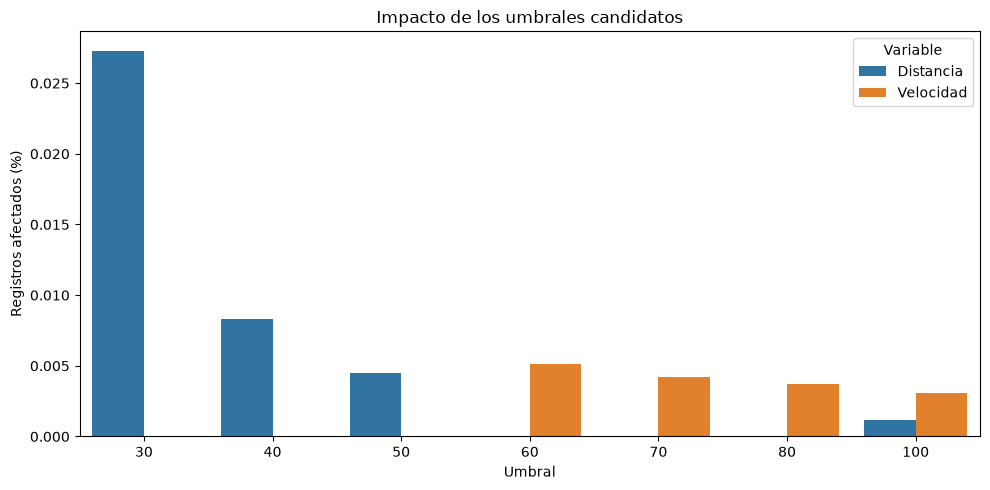

In [14]:
fig, ax = plt.subplots(figsize=(10, 5))

sns.barplot(
    data=threshold_comparison_pd, x='Umbral', y='Porcentaje (%)', hue='Variable', ax=ax
)

ax.set_title('Impacto de los umbrales candidatos')
ax.set_xlabel('Umbral')
ax.set_ylabel('Registros afectados (%)')

fig.tight_layout()

_ = save_figure(fig, '01_threshold_impact', images_dir)

plt.show()

## 4. Selección de los criterios de depuración

Los resultados anteriores permiten seleccionar unos límites conservadores para construir el dataset analítico depurado.

### 4.1. Criterios seleccionados

Se adoptan los siguientes límites:

- **velocidad máxima: 80 mph**;
- **distancia máxima: 50 millas**.

La selección se basa en la combinación de la distribución observada y el impacto de cada umbral.

Para la velocidad, el percentil 99,9 se sitúa en **45,28 mph**. Un límite de 80 mph queda ampliamente por encima de la distribución habitual y afecta únicamente a **426 registros (0,0037 %)**.

Para la distancia, el percentil 99,9 es de **23,30 millas**. El límite de 50 millas mantiene un margen igualmente amplio y afecta a **517 registros (0,0045 %)**.

La aplicación conjunta de ambos criterios afecta a **725 viajes únicos**, equivalentes al **0,0063 %** del dataset procesado de referencia. Entre ellos, **218 registros** cumplen simultáneamente los dos criterios.

Los límites seleccionados buscan eliminar únicamente la cola claramente anómala, evitando utilizar los percentiles como puntos de corte directos y preservando prácticamente la totalidad de los registros.

### 4.2. Construcción del dataset depurado

Los criterios seleccionados se aplican conjuntamente sobre el DataFrame de referencia.

Un viaje se conserva únicamente cuando su velocidad no supera las 80 mph y su distancia no supera las 50 millas.

El resultado se mantiene en caché porque será reutilizado en las comparaciones posteriores entre el dataset de referencia y el dataset depurado.

In [15]:
# ============================================================
# CRITERIOS DEFINITIVOS DE DEPURACIÓN
# ============================================================
SPEED_LIMIT = 80.0
DISTANCE_LIMIT = 50.0


# ============================================================
# DATASET ANALÍTICO DEPURADO
# ============================================================
cleaned_trips_df = (
    nyc_trips_df
    .filter((F.col('speed') <= SPEED_LIMIT) & (F.col('trip_distance') <= DISTANCE_LIMIT))
    .cache()
)

### 4.3. Validación de la depuración

La depuración debe cumplir dos condiciones:

- eliminar exactamente los registros identificados por la combinación de criterios;
- garantizar que los valores máximos del dataset resultante respetan los límites establecidos.

También se cuantifica la proporción de registros conservados para comprobar que la operación afecta únicamente a una fracción mínima del dataset de referencia.

In [16]:
# ============================================================
# MATERIALIZACIÓN DEL DATASET DEPURADO
# ============================================================
cleaned_trip_count = cleaned_trips_df.count()

removed_trip_count = trip_count - cleaned_trip_count

retained_pct = 100 * cleaned_trip_count / trip_count

removed_pct = 100 * removed_trip_count / trip_count


# ============================================================
# COMPROBACIÓN DE LOS LÍMITES
# ============================================================
cleaned_limits = cleaned_trips_df.agg(
    F.max('speed').alias('max_speed'),
    F.max('trip_distance').alias('max_trip_distance')
).first()


# ============================================================
# VALIDACIONES
# ============================================================
assert removed_trip_count == criteria_coincidence['affected_total']

assert cleaned_limits['max_speed'] <= SPEED_LIMIT

assert cleaned_limits['max_trip_distance'] <= DISTANCE_LIMIT


# ============================================================
# RESUMEN DE LA DEPURACIÓN
# ============================================================
cleaning_summary_pd = pd.DataFrame({
    'Indicador': [
        'Registros de referencia',
        'Registros depurados',
        'Registros eliminados',
        'Registros conservados',
        'Registros eliminados',
        'Velocidad máxima resultante',
        'Distancia máxima resultante'
    ],
    'Resultado': [
        f'{trip_count:,}',
        f'{cleaned_trip_count:,}',
        f'{removed_trip_count:,}',
        f'{retained_pct:.4f} %',
        f'{removed_pct:.4f} %',
        f"{cleaned_limits['max_speed']:.2f} mph",
        f"{cleaned_limits['max_trip_distance']:.2f} mi"
    ]
}).set_index('Indicador')

cleaning_summary_pd

,Resultado
Indicador,
Registros de referencia,"11,489,716"
Registros depurados,"11,488,991"
Registros eliminados,725
Registros conservados,99.9937 %
Registros eliminados,0.0063 %
Velocidad máxima resultante,79.81 mph
Distancia máxima resultante,50.00 mi


## 5. Comparación antes y después de la depuración

La eliminación de una fracción muy pequeña de registros no implica necesariamente que su efecto analítico sea pequeño.

Los valores detectados son extraordinariamente extremos, por lo que pueden modificar de forma significativa determinadas estadísticas sensibles, especialmente las medias y los valores máximos.

En esta sección se comparan el **dataset procesado de referencia** y el **dataset depurado** para evaluar:

- el volumen de datos conservado;
- los principales estadísticos de distancia y velocidad;
- la sensibilidad de medias y medianas;
- el efecto sobre los patrones temporales;
- la estabilidad de la estructura territorial;
- la conservación del perfil de la distribución hasta el percentil 99,9.

El objetivo es determinar qué resultados cambian realmente y cuáles permanecen estables después de la depuración.

### 5.1. Impacto sobre el volumen de datos

La primera comparación cuantifica el tamaño de ambos datasets.

Dado que los criterios se han diseñado para actuar únicamente sobre la cola extrema de las distribuciones, se espera conservar prácticamente la totalidad de los viajes.

Además del número de registros se calcula el porcentaje retenido y eliminado respecto al dataset de referencia.

#### Impacto sobre el tamaño del dataset

La aplicación conjunta de los criterios elimina únicamente **725 registros** de los **11.489.716 viajes** del dataset procesado de referencia.

El dataset depurado conserva **11.488.991 viajes**, equivalentes al **99,9937 %** del total, mientras que los registros eliminados representan solo el **0,0063 %**.

La depuración afecta, por tanto, a una fracción extremadamente pequeña del conjunto de datos. Esto permite analizar posteriormente si unas pocas observaciones de magnitud excepcional pueden producir un efecto estadístico desproporcionado.

### 5.2. Comparación de estadísticos descriptivos

Para medir el efecto real de la depuración se calculan sobre ambos datasets los mismos estadísticos de distancia y velocidad.

Se comparan:

- media;
- mediana;
- percentil 95;
- percentil 99;
- máximo.

La comparación permite distinguir entre estadísticas sensibles a valores extremos y medidas robustas que describen el comportamiento habitual de la distribución.

In [17]:
# ============================================================
# ESTADÍSTICOS ANTES Y DESPUÉS
# ============================================================
comparison_stats_pd = pd.DataFrame([
    compute_comparison_stats(nyc_trips_df, 'Referencia'),
    compute_comparison_stats(cleaned_trips_df, 'Depurado')
]).set_index('Dataset')

comparison_stats_pd

,n_trips,avg_distance,median_distance,p95_distance,p99_distance,max_distance,avg_speed,median_speed,p95_speed,p99_speed,max_speed
Dataset,,,,,,,,,,,
Referencia,11489716,14.066442,1.83,10.1,18.41,15420004.5,63.169726,11.33,25.76,36.18,1.928571e+08
Depurado,11488991,3.032227,1.83,10.1,18.40,50.0,12.789428,11.33,25.75,36.16,7.981000e+01


In [18]:
# ============================================================
# COMPARACIÓN DE DISTANCIA
# ============================================================
distance_comparison_pd = comparison_stats_pd[[
    'avg_distance',
    'median_distance',
    'p95_distance',
    'p99_distance',
    'max_distance'
]].rename(
    columns={
        'avg_distance': 'Media',
        'median_distance': 'Mediana',
        'p95_distance': 'P95',
        'p99_distance': 'P99',
        'max_distance': 'Máximo'
    }
)

_ = save_table(distance_comparison_pd, '02_distance_comparison', tables_dir)

distance_comparison_pd.style.format('{:,.2f}')

,Media,Mediana,P95,P99,Máximo
Dataset,,,,,
Referencia,14.07,1.83,10.10,18.41,"15,420,004.50"
Depurado,3.03,1.83,10.10,18.40,50.00


In [19]:
# ============================================================
# COMPARACIÓN DE VELOCIDAD
# ============================================================
speed_comparison_pd = comparison_stats_pd[[
    'avg_speed',
    'median_speed',
    'p95_speed',
    'p99_speed',
    'max_speed'
]].rename(
    columns={
        'avg_speed': 'Media',
        'median_speed': 'Mediana',
        'p95_speed': 'P95',
        'p99_speed': 'P99',
        'max_speed': 'Máximo'
    }
)

_ = save_table(speed_comparison_pd, '03_speed_comparison', tables_dir)

speed_comparison_pd.style.format('{:,.2f}')

,Media,Mediana,P95,P99,Máximo
Dataset,,,,,
Referencia,63.17,11.33,25.76,36.18,"192,857,142.86"
Depurado,12.79,11.33,25.75,36.16,79.81


#### Efecto sobre la distribución

La comparación revela una diferencia muy marcada entre las estadísticas sensibles a valores extremos y las medidas robustas.

En distancia, la media disminuye de aproximadamente **14,07 a 3,03 millas**, mientras que la mediana permanece en **1,83 millas**. El percentil 95 continúa en **10,10 millas** y el percentil 99 apenas varía de **18,41 a 18,40 millas**.

En velocidad se observa el mismo comportamiento. La media pasa de aproximadamente **63,17 a 12,79 mph**, mientras que la mediana permanece en **11,33 mph**. El percentil 95 cambia únicamente de **25,76 a 25,75 mph** y el percentil 99 de **36,18 a 36,16 mph**.

Los máximos, en cambio, pasan de valores extraordinariamente elevados a los límites establecidos por la depuración: **50 millas** y **79,81 mph**.

Esto confirma que los registros eliminados se encontraban muy alejados de la distribución central y que su retirada apenas modifica los percentiles representativos del comportamiento habitual.

### 5.3. Sensibilidad de la media frente a la mediana

Los valores extremos pueden alterar de forma intensa la media incluso cuando representan una proporción mínima del dataset.

La mediana, en cambio, depende de la posición central de la distribución y resulta mucho menos sensible a unas pocas observaciones de magnitud extraordinaria.

Se compara el cambio relativo producido por la depuración sobre ambas medidas para distancia y velocidad.

In [20]:
# ============================================================
# CAMBIO RELATIVO DE MEDIA Y MEDIANA
# ============================================================
sensitivity_pd = pd.DataFrame({
    'Variable': [
        'Distancia · media',
        'Distancia · mediana',
        'Velocidad · media',
        'Velocidad · mediana'
    ],
    'Referencia': [
        comparison_stats_pd.loc['Referencia', 'avg_distance'],
        comparison_stats_pd.loc['Referencia', 'median_distance'],
        comparison_stats_pd.loc['Referencia', 'avg_speed'],
        comparison_stats_pd.loc['Referencia', 'median_speed']
    ],
    'Depurado': [
        comparison_stats_pd.loc['Depurado', 'avg_distance'],
        comparison_stats_pd.loc['Depurado', 'median_distance'],
        comparison_stats_pd.loc['Depurado', 'avg_speed'],
        comparison_stats_pd.loc['Depurado', 'median_speed']
    ]
})

sensitivity_pd['Cambio relativo (%)'] = relative_change(
    sensitivity_pd['Referencia'], sensitivity_pd['Depurado']
).round(4)

sensitivity_pd = sensitivity_pd.set_index('Variable')

sensitivity_pd

,Referencia,Depurado,Cambio relativo (%)
Variable,,,
Distancia · media,14.066442,3.032227,-78.4435
Distancia · mediana,1.830000,1.830000,0.0000
Velocidad · media,63.169726,12.789428,-79.7539
Velocidad · mediana,11.330000,11.330000,0.0000


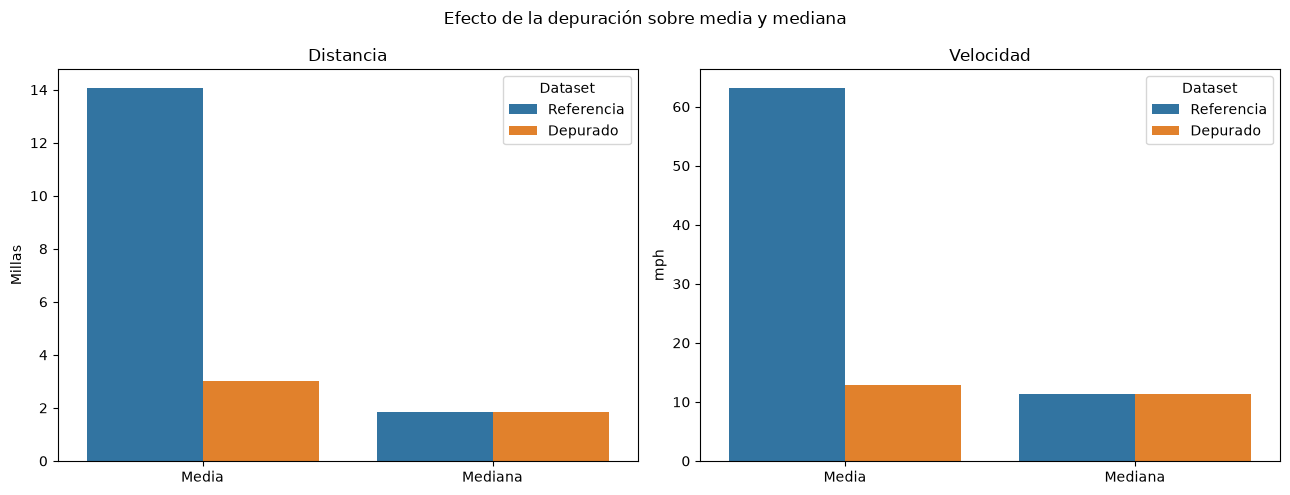

In [21]:
# ============================================================
# COMPARACIÓN VISUAL DE MEDIA Y MEDIANA
# ============================================================
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(13, 5))

distance_plot_pd = pd.DataFrame({
    'Estadístico': [
        'Media',
        'Mediana'
    ],
    'Referencia': [
        comparison_stats_pd.loc['Referencia', 'avg_distance'],
        comparison_stats_pd.loc['Referencia', 'median_distance']
    ],
    'Depurado': [
        comparison_stats_pd.loc['Depurado', 'avg_distance'],
        comparison_stats_pd.loc['Depurado', 'median_distance']
    ]
}).melt(
    id_vars='Estadístico',
    var_name='Dataset',
    value_name='Valor'
)

sns.barplot(
    data=distance_plot_pd, x='Estadístico', y='Valor', hue='Dataset', ax=axes[0]
)

axes[0].set_title('Distancia')
axes[0].set_ylabel('Millas')
axes[0].set_xlabel('')


speed_plot_pd = pd.DataFrame({
    'Estadístico': [
        'Media', 'Mediana'
    ],
    'Referencia': [
        comparison_stats_pd.loc['Referencia', 'avg_speed'],
        comparison_stats_pd.loc['Referencia', 'median_speed']
    ],
    'Depurado': [
        comparison_stats_pd.loc['Depurado', 'avg_speed'],
        comparison_stats_pd.loc['Depurado', 'median_speed']
    ]
}).melt(
    id_vars='Estadístico',
    var_name='Dataset',
    value_name='Valor',
)

sns.barplot(
    data=speed_plot_pd, x='Estadístico', y='Valor', hue='Dataset', ax=axes[1])

axes[1].set_title('Velocidad')
axes[1].set_ylabel('mph')
axes[1].set_xlabel('')

fig.suptitle('Efecto de la depuración sobre media y mediana')

fig.tight_layout()

_ = save_figure(fig, '02_mean_median_comparison', images_dir)

plt.show()

#### Sensibilidad de los estadísticos

Aunque la depuración elimina únicamente el **0,0063 %** de los registros, su efecto sobre las medias es muy elevado:

- la distancia media se reduce aproximadamente un **78,44 %**;
- la velocidad media se reduce aproximadamente un **79,75 %**.

En contraste, las medianas globales de ambas variables no experimentan ningún cambio observable con la precisión utilizada.

La diferencia demuestra que el problema no reside en una alteración general de la distribución, sino en un conjunto extremadamente reducido de registros con magnitudes capaces de dominar el cálculo de la media.

La depuración permite que esta medida vuelva a situarse en una escala coherente con la parte central de la distribución, mientras que los estadísticos robustos confirman la estabilidad del comportamiento habitual.

### 5.4. Distribución temporal de los registros depurados

La depuración elimina una proporción mínima de observaciones, pero resulta necesario comprobar si esos registros se concentran en determinados días de la semana.

Para cada día se compara el número de viajes del dataset de referencia con el número conservado después de aplicar los criterios, obteniendo también el número y porcentaje de registros eliminados.

Esta comparación permite distinguir entre la **frecuencia temporal de los valores extremos** y el efecto que su magnitud puede ejercer posteriormente sobre los estadísticos diarios.

In [22]:
# ============================================================
# RESUMEN TEMPORAL DE REFERENCIA
# ============================================================
reference_daily_df = nyc_trips_df.groupBy('day_of_week').agg(
    F.count('*').alias('reference_trips'),
    F.avg('speed').alias('reference_avg_speed'),
    F.expr('percentile_approx(speed, 0.5, 10000)').alias('reference_median_speed'),
    F.avg('trip_distance').alias('reference_avg_distance'),
    F.expr('percentile_approx(trip_distance, 0.5, 10000)').alias('reference_median_distance')
)


# ============================================================
# RESUMEN TEMPORAL DEPURADO
# ============================================================
cleaned_daily_df = cleaned_trips_df.groupBy('day_of_week').agg(
    F.count('*').alias('cleaned_trips'),
    F.avg('speed').alias('cleaned_avg_speed'),
    F.expr('percentile_approx(speed, 0.5, 10000)').alias('cleaned_median_speed'),
    F.avg('trip_distance').alias('cleaned_avg_distance'),
    F.expr('percentile_approx(trip_distance, 0.5, 10000)').alias('cleaned_median_distance')
)


# ============================================================
# COMPARACIÓN TEMPORAL
# ============================================================
daily_comparison_pd = (
    reference_daily_df
    .join(cleaned_daily_df, on='day_of_week', how='inner')
    .withColumn('removed_trips', F.col('reference_trips') - F.col('cleaned_trips'))
    .withColumn('removed_pct', 100 * F.col('removed_trips') / F.col('reference_trips'))
    .toPandas()
    .set_index('day_of_week')
    .reindex(DAYS_ORDER)
    .reset_index()
)

daily_comparison_pd['Día'] = daily_comparison_pd['day_of_week'].replace(DAY_LABELS)

daily_comparison_pd = daily_comparison_pd.drop(columns='day_of_week').set_index('Día')

daily_comparison_pd['removed_pct'] = daily_comparison_pd['removed_pct'].round(4)

_ = save_table(daily_comparison_pd, '04_daily_comparison', tables_dir)

daily_comparison_pd

,reference_trips,reference_avg_speed,reference_median_speed,reference_avg_distance,reference_median_distance,cleaned_trips,cleaned_avg_speed,cleaned_median_speed,cleaned_avg_distance,cleaned_median_distance,removed_trips,removed_pct
Día,,,,,,,,,,,,
Lunes,1197153,13.304696,11.65,3.177713,1.80,1197067,13.294217,11.64,3.172735,1.80,86,0.0072
Martes,1233286,12.472920,11.06,2.922900,1.78,1233215,12.463569,11.06,2.919403,1.78,71,0.0058
Miércoles,1510473,26.600803,10.56,5.513957,1.80,1510384,12.083459,10.56,2.950842,1.80,89,0.0059
Jueves,1953824,21.965153,10.97,7.418510,1.87,1953704,12.442938,10.97,3.079873,1.87,120,0.0061
Viernes,2004594,204.100467,10.47,37.606275,1.80,2004450,12.032145,10.47,3.011839,1.80,144,0.0072
Sábado,2148723,33.339184,11.64,8.672703,1.86,2148613,13.000095,11.64,2.892503,1.86,110,0.0051
Domingo,1441663,90.604185,13.04,25.919198,2.00,1441558,14.597265,13.04,3.269370,2.00,105,0.0073


#### Distribución de los registros eliminados

Los registros eliminados representan entre aproximadamente el **0,0051 % y el 0,0073 %** de los viajes diarios.

La distribución es reducida y relativamente homogénea durante toda la semana: ningún día concentra una proporción suficientemente elevada de eliminaciones como para modificar de forma apreciable su volumen total.

Esto permite analizar por separado un aspecto diferente: aunque los registros afectados son muy pocos, su magnitud puede alterar considerablemente determinados estadísticos diarios.

### 5.5. Evolución diaria de la velocidad

La velocidad permite observar con especial claridad la diferencia entre **frecuencia de valores extremos** e **impacto estadístico**.

Se comparan para cada día de la semana la media y la mediana antes y después de la depuración.

La media es sensible a registros de magnitud excepcional, mientras que la mediana describe la posición central de la distribución. La representación conjunta permite comprobar si la depuración corrige valores distorsionados sin modificar el comportamiento habitual de los viajes.

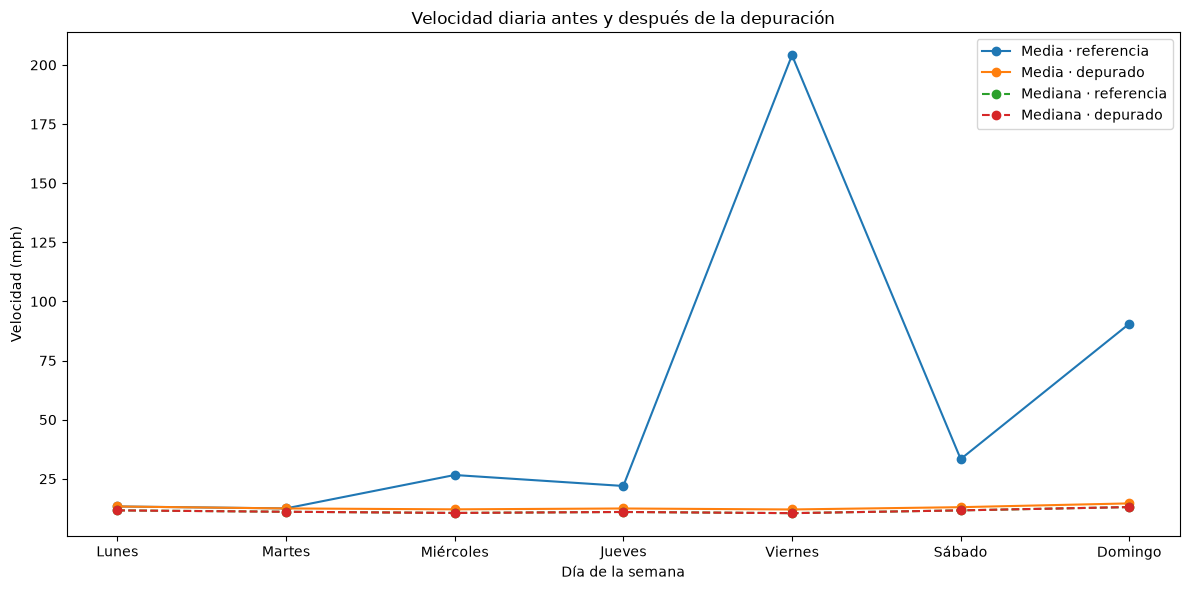

In [23]:
# ============================================================
# VELOCIDAD DIARIA ANTES Y DESPUÉS
# ============================================================
daily_speed_plot_pd = daily_comparison_pd[[
    'reference_avg_speed',
    'cleaned_avg_speed',
    'reference_median_speed',
    'cleaned_median_speed'
]].reset_index()

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    daily_speed_plot_pd['Día'], daily_speed_plot_pd['reference_avg_speed'], marker='o',
    label='Media · referencia'
)

ax.plot(
    daily_speed_plot_pd['Día'], daily_speed_plot_pd['cleaned_avg_speed'], marker='o',
    label='Media · depurado'
)

ax.plot(
    daily_speed_plot_pd['Día'], daily_speed_plot_pd['reference_median_speed'], marker='o',
    linestyle='--', label='Mediana · referencia'
)

ax.plot(
    daily_speed_plot_pd['Día'], daily_speed_plot_pd['cleaned_median_speed'], marker='o',
    linestyle='--', label='Mediana · depurado'
)

ax.set_title('Velocidad diaria antes y después de la depuración')
ax.set_xlabel('Día de la semana')
ax.set_ylabel('Velocidad (mph)')

ax.legend()

fig.tight_layout()

_ = save_figure(fig, '03_daily_speed_comparison', images_dir)

plt.show()

#### Efecto de la depuración sobre la velocidad diaria

La diferencia entre media y mediana confirma que el efecto de los registros extremos es muy desigual según el estadístico utilizado.

El caso más acusado se produce el **viernes**, cuya velocidad media disminuye de aproximadamente **204,10 a 12,03 mph**. El **domingo** pasa de **90,60 a 14,60 mph** y el **sábado** de **33,34 a 13,00 mph**.

En cambio, las velocidades medianas permanecen prácticamente invariantes durante toda la semana.

La depuración no modifica, por tanto, el patrón central de velocidad de los viajes. Su principal efecto consiste en eliminar la influencia desproporcionada que unas pocas observaciones ejercían sobre las medias diarias.

### 5.6. Evolución diaria de la distancia

La comparación temporal se amplía a la distancia recorrida para comprobar si los valores extremos producen un efecto similar al observado sobre la velocidad.

Se representan conjuntamente la **media** y la **mediana diaria** antes y después de la depuración.

Si los registros eliminados se concentran principalmente en la cola extrema, se espera que la media experimente una corrección apreciable mientras que la mediana conserve prácticamente el mismo comportamiento semanal.

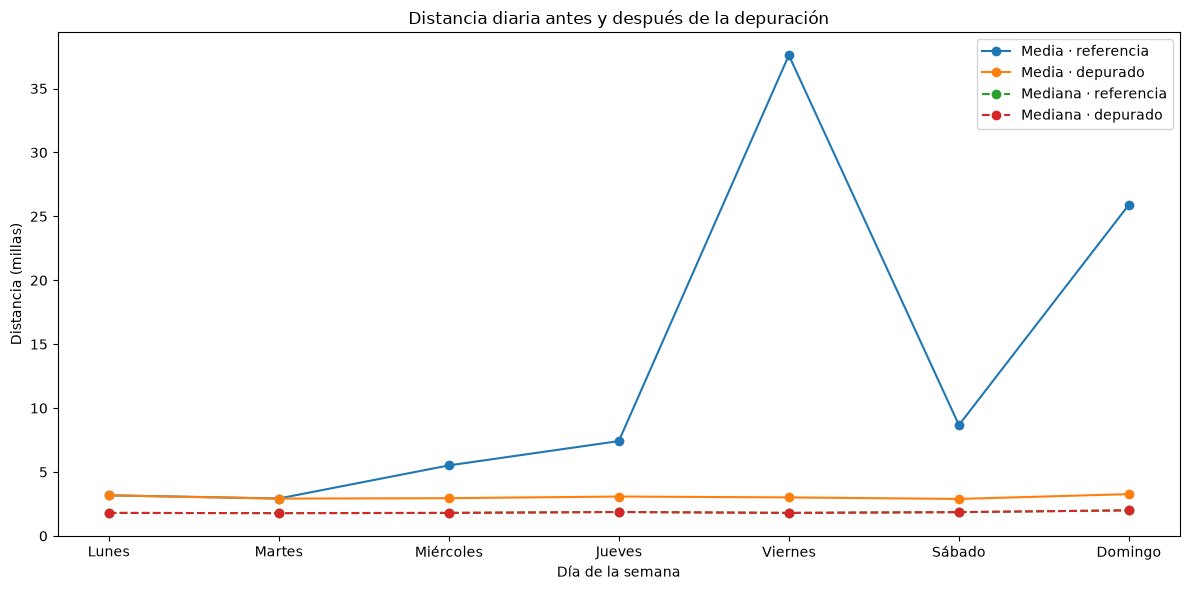

In [24]:
# ============================================================
# DISTANCIA DIARIA ANTES Y DESPUÉS
# ============================================================
daily_distance_plot_pd = daily_comparison_pd[[
    'reference_avg_distance',
    'cleaned_avg_distance',
    'reference_median_distance',
    'cleaned_median_distance'
]].reset_index()

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    daily_distance_plot_pd['Día'], daily_distance_plot_pd['reference_avg_distance'],
    marker='o', label='Media · referencia'
)

ax.plot(
    daily_distance_plot_pd['Día'], daily_distance_plot_pd['cleaned_avg_distance'],
    marker='o', label='Media · depurado'
)

ax.plot(
    daily_distance_plot_pd['Día'], daily_distance_plot_pd['reference_median_distance'],
    marker='o', linestyle='--', label='Mediana · referencia'
)

ax.plot(
    daily_distance_plot_pd['Día'], daily_distance_plot_pd['cleaned_median_distance'],
    marker='o', linestyle='--', label='Mediana · depurado'
)

ax.set_title('Distancia diaria antes y después de la depuración')
ax.set_xlabel('Día de la semana')
ax.set_ylabel('Distancia (millas)')

ax.legend()

fig.tight_layout()

_ = save_figure(fig, '04_daily_distance_comparison', images_dir)

plt.show()

#### Efecto de la depuración sobre la distancia diaria

La distancia reproduce el mismo patrón observado en la velocidad.

Las diferencias son especialmente acusadas en algunos días. La distancia media del **viernes** disminuye de aproximadamente **37,61 a 3,01 millas**, mientras que el **domingo** pasa de **25,92 a 3,27 millas** y el **sábado** de **8,67 a 2,89 millas**.

También se corrigen valores elevados durante el miércoles y el jueves, cuyas medias quedan próximas a las tres millas después de la depuración.

Frente a estos cambios, las medianas diarias permanecen invariantes con la precisión utilizada, situándose entre **1,78 y 2,00 millas**.

La coincidencia del comportamiento observado en distancia y velocidad refuerza la conclusión anterior: la depuración actúa fundamentalmente sobre una cola extrema de muy baja frecuencia, sin desplazar la parte central de las distribuciones.

### 5.7. Impacto territorial de la depuración

Los criterios de depuración se aplican sobre características del viaje y no directamente sobre su localización. Sin embargo, determinados tipos de trayecto pueden concentrarse territorialmente.

Para comprobar si la eliminación de valores extremos presenta diferencias espaciales, cada viaje se asigna a su **distrito comunitario de origen** mediante Apache Sedona.

Para cada distrito se comparan:

- número de viajes en el dataset de referencia;
- número de viajes conservados tras la depuración;
- registros eliminados;
- porcentaje eliminado;
- posición del distrito por volumen antes y después de la depuración.

El análisis utiliza únicamente el distrito de recogida, ya que el objetivo no es repetir el análisis geoespacial completo del notebook de referencia, sino evaluar si los criterios de calidad de datos modifican de forma desigual la distribución territorial de la actividad.

In [25]:
# ============================================================
# REFERENCIA DE DISTRITOS
# ============================================================
districts_pd = pd.read_csv(io.StringIO(DISTRICTS_REFERENCE), names=['BoroCD', 'district'])


# ============================================================
# CARGA DE GEOMETRÍAS
# ============================================================
if not geojson_path.exists():
    raise FileNotFoundError(f'No se encuentra el fichero geográfico: {geojson_path}')

# El GeoJSON contiene los polígonos de los distritos comunitarios
gdf_raw = gpd.read_file(geojson_path)

# Los nombres se incorporan mediante el identificador BoroCD
nyc_gdf = gdf_raw.merge(districts_pd, on='BoroCD', how='inner')


# ============================================================
# POLÍGONOS DE LOS DISTRITOS
# ============================================================
# GeoPandas mantiene las geometrías localmente; se serializan a WKT para trasladarlas a Spark
nyc_gdf['district_geom'] = nyc_gdf['geometry'].apply(lambda geometry: geometry.wkt)

# Sedona reconstruye el WKT como geometría espacial
districts_df = (
    spark
    .createDataFrame(nyc_gdf[['district', 'district_geom']])
    .withColumn('district_geom', F.expr('ST_GeomFromWKT(district_geom)'))
)

districts_df.printSchema()


# ============================================================
# DISTRITOS DE RECOGIDA
# ============================================================
pickup_districts = districts_df.withColumnRenamed('district', 'pickup_district')


# ============================================================
# ASIGNACIÓN TERRITORIAL
# ============================================================
district_quality_df = (
    nyc_trips_df
    .withColumn('pickup_point', F.expr('ST_Point(pickup_longitude, pickup_latitude)'))
    .join(
        F.broadcast(pickup_districts),
        F.expr('ST_Contains(district_geom, pickup_point)'),
        how='left'
    )
    .drop('pickup_point', 'district_geom')
    .select('pickup_district', 'trip_distance', 'speed')
    .cache()
)

root
 |-- district: string (nullable = true)
 |-- district_geom: geometry (nullable = true)



In [26]:
# ============================================================
# VALIDACIÓN DE LA ASIGNACIÓN TERRITORIAL
# ============================================================
district_quality_count = district_quality_df.count()

assigned_district_count = district_quality_df.filter(F.col('pickup_district').isNotNull()).count()

district_coverage_pct = 100 * assigned_district_count / district_quality_count

spatial_join_ok = (district_quality_count == trip_count)

assert spatial_join_ok

spatial_assignment_summary_pd = pd.DataFrame({
    'Indicador': [
        'Viajes antes del spatial join',
        'Viajes después del spatial join',
        'Viajes con distrito asignado',
        'Cobertura territorial',
        'Conservación de filas'
    ],
    'Resultado': [
        f'{trip_count:,}',
        f'{district_quality_count:,}',
        f'{assigned_district_count:,}',
        f'{district_coverage_pct:.2f} %',
        'OK'
    ]
}).set_index('Indicador')

spatial_assignment_summary_pd

,Resultado
Indicador,
Viajes antes del spatial join,"11,489,716"
Viajes después del spatial join,"11,489,716"
Viajes con distrito asignado,"10,665,874"
Cobertura territorial,92.83 %
Conservación de filas,OK


In [27]:
# ============================================================
# IMPACTO DE LA DEPURACIÓN POR DISTRITO
# ============================================================
clean_condition = (F.col('speed') <= SPEED_LIMIT) & (F.col('trip_distance') <= DISTANCE_LIMIT)

district_comparison_df = (
    district_quality_df
    .filter(F.col('pickup_district').isNotNull())
    .groupBy('pickup_district')
    .agg(
        F.count('*').alias('reference_trips'),
        F.sum(clean_condition.cast('int')).alias('cleaned_trips')
    )
    .withColumn('removed_trips', F.col('reference_trips') - F.col('cleaned_trips'))
    .withColumn('removed_pct', 100 * F.col('removed_trips') / F.col('reference_trips'))
)

district_comparison_pd = district_comparison_df.toPandas()


# ============================================================
# POSICIÓN DE LOS DISTRITOS
# ============================================================
district_comparison_pd['reference_rank'] = (
    district_comparison_pd['reference_trips'].rank(method='min', ascending=False).astype(int)
)

district_comparison_pd['cleaned_rank'] = (
    district_comparison_pd['cleaned_trips'].rank(method='min', ascending=False).astype(int)
)

district_comparison_pd['rank_change'] = (
    district_comparison_pd['reference_rank'] - district_comparison_pd['cleaned_rank']
)

district_comparison_pd['removed_pct'] = district_comparison_pd['removed_pct'].round(4)

district_comparison_pd['Distrito'] = (
    district_comparison_pd['pickup_district'].replace(DISTRICT_LABELS)
)


# ============================================================
# RANKING DE LOS DISTRITOS
# ============================================================
top_district_comparison_pd = district_comparison_pd.sort_values(
    'reference_trips',
    ascending=False
).head(15)[[
    'Distrito',
    'reference_trips',
    'cleaned_trips',
    'removed_trips',
    'removed_pct',
    'reference_rank',
    'cleaned_rank',
    'rank_change'
]].rename(columns={
    'reference_trips': 'Referencia',
    'cleaned_trips': 'Depurado',
    'removed_trips': 'Eliminados',
    'removed_pct': 'Eliminados (%)',
    'reference_rank': 'Posición referencia',
    'cleaned_rank': 'Posición depurado',
    'rank_change': 'Cambio posición'
}).set_index('Distrito')

_ = save_table(top_district_comparison_pd, '05_district_comparison', tables_dir)

top_district_comparison_pd

,Referencia,Depurado,Eliminados,Eliminados (%),Posición referencia,Posición depurado,Cambio posición
Distrito,,,,,,,
Midtown,2742852,2742740,112,0.0041,1,1,0
Upper East Side,1596827,1596782,45,0.0028,2,2,0
Chelsea / Clinton,1224867,1224809,58,0.0047,3,3,0
Stuyvesant / Turtle Bay,1211238,1211187,51,0.0042,4,4,0
Greenwich / SoHo,1121318,1121282,36,0.0032,5,5,0
Upper West Side,988038,988010,28,0.0028,6,6,0
LES / Chinatown,670702,670671,31,0.0046,7,7,0
Financial District,526959,526935,24,0.0046,8,8,0
East Harlem,99715,99711,4,0.0040,9,9,0


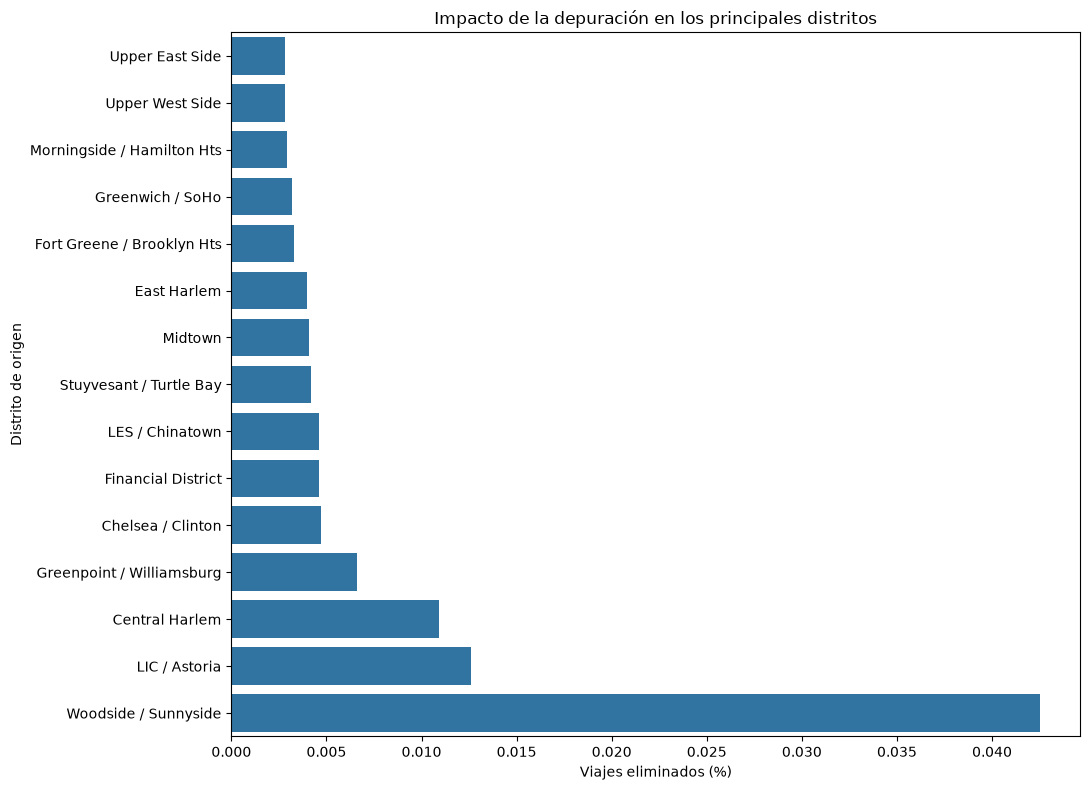

In [28]:
# ============================================================
# IMPACTO RELATIVO POR DISTRITO
# ============================================================
district_impact_plot_pd = top_district_comparison_pd.reset_index().sort_values(
    'Eliminados (%)', ascending=True
)

fig, ax = plt.subplots(figsize=(11, 8))

sns.barplot(
    data=district_impact_plot_pd, x='Eliminados (%)', y='Distrito', ax=ax
)

ax.set_title('Impacto de la depuración en los principales distritos')
ax.set_xlabel('Viajes eliminados (%)')
ax.set_ylabel('Distrito de origen')

fig.tight_layout()

_ = save_figure(fig, '05_district_cleaning_impact', images_dir)

plt.show()

#### Estabilidad territorial de la actividad

El impacto territorial de la depuración es igualmente reducido.

Los **15 distritos con mayor volumen de recogidas conservan exactamente la misma posición** antes y después del filtrado. Midtown continúa ocupando la primera posición, seguido por Upper East Side, Chelsea / Clinton y Stuyvesant / Turtle Bay.

En términos absolutos, Midtown es el distrito del grupo en el que se eliminan más viajes, con **112 registros**, pero representan únicamente el **0,0041 %** de su actividad.

Las mayores proporciones relativas dentro de los 15 distritos aparecen en **Woodside / Sunnyside (0,0425 %)**, **LIC / Astoria (0,0126 %)** y **Central Harlem (0,0109 %)**, valores que siguen siendo muy reducidos.

La depuración no altera, por tanto, la jerarquía territorial de los principales distritos. Esto constituye una evidencia adicional de que los criterios utilizados corrigen registros extremos sin modificar la estructura espacial general de la actividad.

### 5.8. Estabilidad del perfil de percentiles

Las comparaciones anteriores muestran que las medianas y los percentiles altos apenas se modifican tras la depuración.

Para comprobar hasta qué punto se conserva la distribución se amplía el análisis hasta el **percentil 99,9**, comparando el perfil de distancia y velocidad del dataset de referencia con el dataset depurado.

Esta representación permite diferenciar entre una modificación general de la cola superior y la eliminación de un conjunto muy reducido de observaciones situadas mucho más allá de la distribución habitual.

In [29]:
# ============================================================
# PERFIL DE PERCENTILES
# ============================================================
percentile_expression_distance = (
    'percentile_approx(trip_distance, array(0.50, 0.95, 0.99, 0.999), 10000)'
)

percentile_expression_speed = (
    'percentile_approx(speed, array(0.50, 0.95, 0.99, 0.999), 10000)'
)

reference_distance_q, reference_speed_q = get_percentile_profile(
    nyc_trips_df, percentile_expression_distance, 'distance', percentile_expression_speed, 'speed'
)

cleaned_distance_q, cleaned_speed_q = get_percentile_profile(
    cleaned_trips_df, percentile_expression_distance, 'distance',
    percentile_expression_speed, 'speed'
)

percentile_profile_pd = pd.DataFrame({
    'Percentil': [
        'P50',
        'P95',
        'P99',
        'P99.9'
    ],
    'Distancia · referencia': reference_distance_q,
    'Distancia · depurado': cleaned_distance_q,
    'Velocidad · referencia': reference_speed_q,
    'Velocidad · depurado': cleaned_speed_q
})

_ = save_table(percentile_profile_pd, '06_percentile_profile', tables_dir)

percentile_profile_pd

,Percentil,Distancia · referencia,Distancia · depurado,Velocidad · referencia,Velocidad · depurado
0,P50,1.83,1.83,11.33,11.33
1,P95,10.10,10.10,25.76,25.75
2,P99,18.41,18.40,36.18,36.16
3,P99.9,23.30,23.17,45.28,45.08


In [30]:
# ============================================================
# VARIACIÓN RELATIVA DEL PERFIL
# ============================================================
distance_profile_change_pct = relative_change(
    percentile_profile_pd['Distancia · referencia'],
    percentile_profile_pd['Distancia · depurado']
).abs()

speed_profile_change_pct = relative_change(
    percentile_profile_pd['Velocidad · referencia'],
    percentile_profile_pd['Velocidad · depurado']
).abs()

max_percentile_profile_change_pct = max(
    distance_profile_change_pct.max(), speed_profile_change_pct.max()
)

print(
    f'Variación relativa máxima del perfil P50–P99.9: {max_percentile_profile_change_pct:.2f} %'
)

Variación relativa máxima del perfil P50–P99.9: 0.56 %


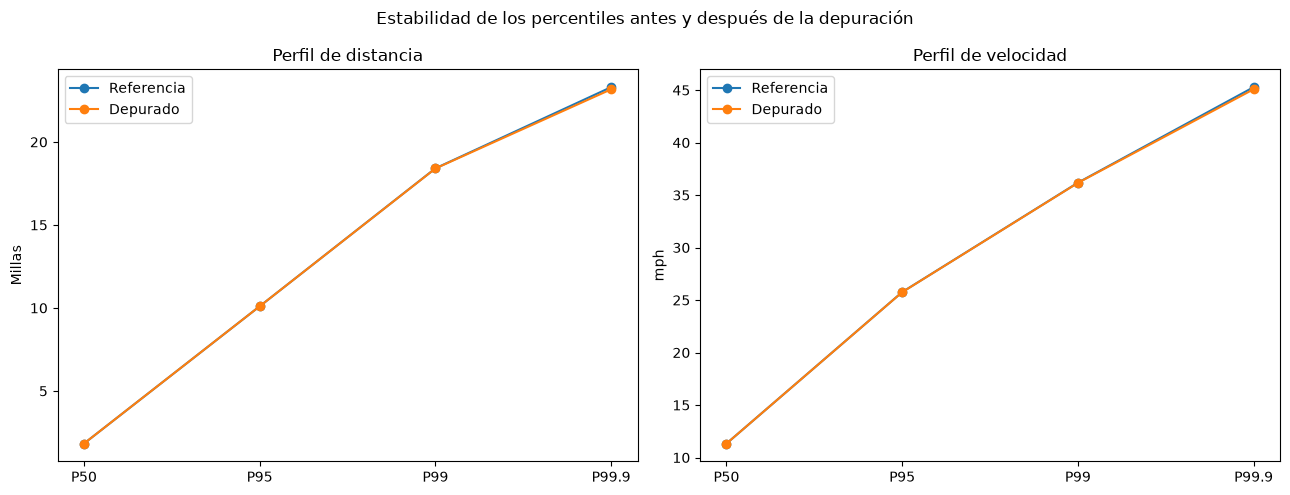

In [31]:
# ============================================================
# PERFIL VISUAL DE PERCENTILES
# ============================================================
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(13, 5))

axes[0].plot(
    percentile_profile_pd['Percentil'], percentile_profile_pd['Distancia · referencia'],
    marker='o', label='Referencia'
)

axes[0].plot(
    percentile_profile_pd['Percentil'], percentile_profile_pd['Distancia · depurado'],
    marker='o', label='Depurado'
)

axes[0].set_title('Perfil de distancia')
axes[0].set_ylabel('Millas')

axes[0].legend()

axes[1].plot(
    percentile_profile_pd['Percentil'], percentile_profile_pd['Velocidad · referencia'],
    marker='o', label='Referencia'
)

axes[1].plot(
    percentile_profile_pd['Percentil'], percentile_profile_pd['Velocidad · depurado'],
    marker='o', label='Depurado'
)

axes[1].set_title('Perfil de velocidad')
axes[1].set_ylabel('mph')

axes[1].legend()

fig.suptitle('Estabilidad de los percentiles antes y después de la depuración')

fig.tight_layout()

_ = save_figure(fig, '06_percentile_profile_comparison', images_dir)

plt.show()

#### Conservación de la distribución hasta el percentil 99,9

La comparación confirma que la depuración apenas modifica el perfil de las distribuciones incluso al analizar percentiles muy elevados.

En **distancia**, la mediana y el percentil 95 permanecen invariantes con la precisión utilizada. El percentil 99 pasa únicamente de **18,41 a 18,40 millas**, mientras que el percentil 99,9 disminuye de **23,30 a 23,17 millas**.

En **velocidad**, la mediana permanece en **11,33 mph**, el percentil 95 cambia de **25,76 a 25,75 mph**, el percentil 99 de **36,18 a 36,16 mph** y el percentil 99,9 de **45,28 a 45,08 mph**.

Incluso en el percentil 99,9, la variación relativa es inferior aproximadamente al **0,6 %** en ambas variables.

Este resultado es especialmente relevante porque muestra que la depuración no produce un desplazamiento general de la cola superior de las distribuciones. La gran corrección observada en las medias procede de un número extraordinariamente reducido de observaciones situadas mucho más allá del comportamiento representado incluso por el percentil 99,9.

## 6. Persistencia del dataset depurado

### 6.1. Escritura en formato Parquet

El resultado principal del proceso de calidad de datos es el dataset analítico depurado.

Para conservar este resultado sin volver a ejecutar todo el pipeline, el DataFrame se persiste en formato **Parquet**, un formato columnar adecuado para el procesamiento distribuido con Spark.

La salida se particiona por día de la semana, lo que mantiene una estructura lógica para posteriores análisis temporales y permite a Spark aplicar poda de particiones cuando una consulta se restringe a determinados días.

Se utiliza compresión **Snappy**, habitual en ecosistemas Spark por su equilibrio entre velocidad de lectura/escritura y reducción de tamaño.

In [32]:
# ============================================================
# PERSISTENCIA DEL DATASET DEPURADO
# ============================================================
cleaned_parquet_path = outputs_dir / 'nyc_taxi_cleaned_parquet'

(
    cleaned_trips_df
    .write
    .mode('overwrite')
    .option('compression', 'snappy')
    .partitionBy('day_of_week')
    .parquet(str(cleaned_parquet_path))
)

### 6.2. Validación de la persistencia

Después de la escritura se vuelve a cargar el dataset desde Parquet.

La validación comprueba:

- que el número de registros coincide con el DataFrame depurado;
- que se conservan todas las columnas;
- que los tipos de datos se mantienen;
- que los límites de velocidad y distancia continúan respetándose después de la relectura.

De este modo, el fichero persistido queda validado como resultado reproducible del proceso de depuración.

In [33]:
# ============================================================
# RELECTURA DEL DATASET DEPURADO
# ============================================================
cleaned_parquet_df = (
    spark
    .read
    .parquet(str(cleaned_parquet_path))
)


# ============================================================
# VALIDACIÓN
# ============================================================
parquet_rows = cleaned_parquet_df.count()

parquet_limits = cleaned_parquet_df.agg(
    F.max('speed').alias('max_speed'),
    F.max('trip_distance').alias('max_trip_distance')
).first()

assert (parquet_rows == cleaned_trip_count)
assert (set(cleaned_parquet_df.columns) == set(cleaned_trips_df.columns))
assert (dict(cleaned_parquet_df.dtypes) == dict(cleaned_trips_df.dtypes))
assert (parquet_limits['max_speed'] <= SPEED_LIMIT)
assert (parquet_limits['max_trip_distance'] <= DISTANCE_LIMIT)


# ============================================================
# RESUMEN DE LA PERSISTENCIA
# ============================================================
parquet_size_mb = (
    sum(file.stat().st_size for file in cleaned_parquet_path.rglob('*') if file.is_file()) / 1024**2
)

parquet_summary_pd = pd.DataFrame({
    'Indicador': [
        'Registros releídos',
        'Columnas',
        'Particionado',
        'Compresión',
        'Tamaño aproximado',
        'Velocidad máxima',
        'Distancia máxima'
    ],
    'Resultado': [
        f'{parquet_rows:,}',
        len(cleaned_parquet_df.columns),
        'day_of_week',
        'Snappy',
        f'{parquet_size_mb:,.2f} MB',
        f"{parquet_limits['max_speed']:.2f} mph",
        f"{parquet_limits['max_trip_distance']:.2f} mi"
    ]
}).set_index('Indicador')

_ = save_table(parquet_summary_pd, '07_parquet_summary', tables_dir)

parquet_summary_pd

,Resultado
Indicador,
Registros releídos,"11,488,991"
Columnas,23
Particionado,day_of_week
Compresión,Snappy
Tamaño aproximado,363.22 MB
Velocidad máxima,79.81 mph
Distancia máxima,50.00 mi


### 6.3. Prueba de reutilización analítica

La validación estructural confirma que el dataset persistido conserva filas, columnas y tipos de datos.

Como comprobación adicional se ejecuta sobre el Parquet releído una agregación temporal independiente y se compara con los recuentos diarios obtenidos directamente desde el DataFrame depurado.

Esta prueba permite verificar no solo la integridad del fichero, sino también su reutilización efectiva como fuente para análisis posteriores.

In [34]:
# ============================================================
# RECUENTO DIARIO DESDE PARQUET
# ============================================================
parquet_daily_df = cleaned_parquet_df.groupBy('day_of_week').agg(
    F.count('*').alias('parquet_trips')
)


# ============================================================
# COMPARACIÓN CON EL DATAFRAME DEPURADO
# ============================================================
parquet_daily_validation_df = (
    cleaned_daily_df
    .select('day_of_week', 'cleaned_trips')
    .join(parquet_daily_df, on='day_of_week', how='inner')
    .withColumn('difference', F.col('parquet_trips') - F.col('cleaned_trips'))
)

parquet_daily_validation_pd = (
    parquet_daily_validation_df
    .toPandas()
    .set_index('day_of_week')
    .reindex(DAYS_ORDER)
    .reset_index()
)

parquet_daily_validation_pd['Día'] = parquet_daily_validation_pd['day_of_week'].replace(DAY_LABELS)

parquet_daily_validation_pd = parquet_daily_validation_pd.drop(
    columns='day_of_week'
).set_index('Día')

assert (parquet_daily_validation_pd['difference'] == 0).all()

parquet_daily_validation_pd

,cleaned_trips,parquet_trips,difference
Día,,,
Lunes,1197067,1197067,0
Martes,1233215,1233215,0
Miércoles,1510384,1510384,0
Jueves,1953704,1953704,0
Viernes,2004450,2004450,0
Sábado,2148613,2148613,0
Domingo,1441558,1441558,0


## 7. Estabilidad de los resultados

La comparación anterior permite evaluar si las principales conclusiones estadísticas, temporales y territoriales dependen de los valores extremos detectados.

Una depuración adecuada debería corregir las estadísticas distorsionadas sin modificar de forma sustancial los patrones que describen el comportamiento habitual de los viajes ni comprometer la integridad del resultado persistido.

Por este motivo se combinan indicadores estadísticos, temporales, territoriales y técnicos antes de cerrar la validación del dataset depurado.

In [35]:
# ============================================================
# INDICADORES DE ESTABILIDAD
# ============================================================
reference_busiest_day = daily_comparison_pd['reference_trips'].idxmax()

cleaned_busiest_day = daily_comparison_pd['cleaned_trips'].idxmax()


# ============================================================
# PERCENTILES EXTREMOS PARA EL RESUMEN DE ESTABILIDAD
# ============================================================
p999_row = percentile_profile_pd.loc[percentile_profile_pd['Percentil'] == 'P99.9'].iloc[0]


# ============================================================
# RESUMEN DE ESTABILIDAD
# ============================================================
stability_summary_pd = pd.DataFrame({
    'Indicador': [
        'Viajes analizados',
        'Distancia mediana',
        'Velocidad mediana',
        'P99 distancia',
        'P99 velocidad',
        'P99.9 distancia',
        'P99.9 velocidad',
        'Día con mayor volumen'
    ],
    'Referencia': [
        f'{trip_count:,}',
        f"{comparison_stats_pd.loc['Referencia', 'median_distance']:.2f} mi",
        f"{comparison_stats_pd.loc['Referencia', 'median_speed']:.2f} mph",
        f"{comparison_stats_pd.loc['Referencia', 'p99_distance']:.2f} mi",
        f"{comparison_stats_pd.loc['Referencia', 'p99_speed']:.2f} mph",
        f"{p999_row['Distancia · referencia']:.2f} mi",
        f"{p999_row['Velocidad · referencia']:.2f} mph",
        reference_busiest_day
    ],
    'Depurado': [
        f'{cleaned_trip_count:,}',
        f"{comparison_stats_pd.loc['Depurado', 'median_distance']:.2f} mi",
        f"{comparison_stats_pd.loc['Depurado', 'median_speed']:.2f} mph",
        f"{comparison_stats_pd.loc['Depurado', 'p99_distance']:.2f} mi",
        f"{comparison_stats_pd.loc['Depurado', 'p99_speed']:.2f} mph",
        f"{p999_row['Distancia · depurado']:.2f} mi",
        f"{p999_row['Velocidad · depurado']:.2f} mph",
        cleaned_busiest_day
    ]
}).set_index('Indicador')

_ = save_table(stability_summary_pd, '08_stability_summary', tables_dir)

stability_summary_pd

,Referencia,Depurado
Indicador,,
Viajes analizados,"11,489,716","11,488,991"
Distancia mediana,1.83 mi,1.83 mi
Velocidad mediana,11.33 mph,11.33 mph
P99 distancia,18.41 mi,18.40 mi
P99 velocidad,36.18 mph,36.16 mph
P99.9 distancia,23.30 mi,23.17 mi
P99.9 velocidad,45.28 mph,45.08 mph
Día con mayor volumen,Sábado,Sábado


### 7.1. Interpretación

La comparación confirma que la depuración corrige las estadísticas afectadas por los valores extremos sin modificar las principales características de la distribución.

La distancia y la velocidad medianas permanecen invariantes, mientras que los percentiles elevados presentan cambios mínimos. Esta estabilidad se mantiene incluso al ampliar el análisis hasta el **percentil 99,9**.

Considerando conjuntamente los perfiles P50, P95, P99 y P99,9 de distancia y velocidad, la variación relativa máxima observada tras la depuración es de aproximadamente **0,56 %**.

Por tanto, la eliminación del **0,0063 %** de los registros corrige unas medias fuertemente distorsionadas sin alterar de forma sustancial ni la parte central ni la cola alta representativa de las distribuciones.

La principal modificación aparece en las **medias**, que estaban fuertemente condicionadas por un número extraordinariamente pequeño de observaciones. Una vez retiradas, estas medidas se sitúan en valores compatibles con el resto de la distribución.

Este resultado justifica la coexistencia de las dos versiones del análisis:

- el **dataset de referencia** conserva el procesamiento original y garantiza su reproducibilidad;
- el **dataset depurado** proporciona una base más adecuada cuando el objetivo requiere utilizar estadísticas sensibles a valores extremos.

### 7.2. Validación integral del resultado depurado

La calidad del dataset resultante no se evalúa únicamente por la desaparición de valores extremos.

Una depuración consistente debe satisfacer simultáneamente varias condiciones:

- conservar correctamente los registros no afectados;
- respetar los límites establecidos;
- mantener estables las medidas que describen la distribución central;
- preservar los principales patrones temporales y territoriales;
- persistirse y releerse sin pérdida de información;
- producir los mismos resultados cuando el análisis se ejecuta sobre el dataset persistido.

Las comprobaciones siguientes resumen estas condiciones de forma explícita.

In [36]:
# ============================================================
# VALIDACIÓN INTEGRAL DEL RESULTADO DEPURADO
# ============================================================
row_conservation_ok = cleaned_trip_count + removed_trip_count == trip_count

limits_ok = (
    cleaned_limits['max_speed'] <= SPEED_LIMIT
    and cleaned_limits['max_trip_distance'] <= DISTANCE_LIMIT
)

median_distance_stable = (
    round(comparison_stats_pd.loc['Referencia', 'median_distance'], 2)
    == round(comparison_stats_pd.loc['Depurado', 'median_distance'], 2)
)

median_speed_stable = (
    round(comparison_stats_pd.loc['Referencia', 'median_speed'], 2)
    == round(comparison_stats_pd.loc['Depurado', 'median_speed'], 2)
)

busiest_day_stable = (reference_busiest_day == cleaned_busiest_day)

top_districts_stable = (top_district_comparison_pd['Cambio posición'] == 0).all()

parquet_structure_ok = (
    parquet_rows == cleaned_trip_count
    and set(cleaned_parquet_df.columns)
    == set(cleaned_trips_df.columns)
    and dict(cleaned_parquet_df.dtypes)
    == dict(cleaned_trips_df.dtypes)
)

parquet_analysis_ok = (parquet_daily_validation_pd['difference'] == 0).all()


# ============================================================
# RESUMEN DE VALIDACIÓN
# ============================================================
validation_summary_pd = pd.DataFrame({
    'Comprobación': [
        'Conservación de registros',
        'Límites de depuración',
        'Mediana de distancia',
        'Mediana de velocidad',
        'Día de mayor volumen',
        'Ranking territorial · top 15',
        'Perfil P50–P99.9',
        'Conservación en asignación territorial',
        'Persistencia Parquet',
        'Reutilización analítica del Parquet'
    ],
    'Ámbito': [
        'Integridad',
        'Calidad',
        'Estabilidad estadística',
        'Estabilidad estadística',
        'Estabilidad temporal',
        'Estabilidad territorial',
        'Estabilidad distribucional',
        'Integridad espacial',
        'Persistencia',
        'Reproducibilidad'
    ],
    'Estado': [
        'OK' if row_conservation_ok else 'REVISAR',
        'OK' if limits_ok else 'REVISAR',
        'Estable' if median_distance_stable else 'Cambio',
        'Estable' if median_speed_stable else 'Cambio',
        'Estable' if busiest_day_stable else 'Cambio',
        'Estable' if top_districts_stable else 'Cambio',
        f'Δ máx. {max_percentile_profile_change_pct:.2f} %',
        'OK' if spatial_join_ok else 'REVISAR',
        'OK' if parquet_structure_ok else 'REVISAR',
        'OK' if parquet_analysis_ok else 'REVISAR'
    ]
}).set_index('Comprobación')

_ = save_table(validation_summary_pd, '09_validation_summary', tables_dir)

validation_summary_pd

,Ámbito,Estado
Comprobación,,
Conservación de registros,Integridad,OK
Límites de depuración,Calidad,OK
Mediana de distancia,Estabilidad estadística,Estable
Mediana de velocidad,Estabilidad estadística,Estable
Día de mayor volumen,Estabilidad temporal,Estable
Ranking territorial · top 15,Estabilidad territorial,Estable
Perfil P50–P99.9,Estabilidad distribucional,Δ máx. 0.56 %
Conservación en asignación territorial,Integridad espacial,OK
Persistencia Parquet,Persistencia,OK


In [37]:
# ============================================================
# VALIDACIÓN TÉCNICA
# ============================================================
technical_validation_ok = (
    row_conservation_ok
    and limits_ok
    and spatial_join_ok
    and parquet_structure_ok
    and parquet_analysis_ok
)

assert technical_validation_ok

print('Validación técnica del dataset depurado: OK')

Validación técnica del dataset depurado: OK


### 7.3. Síntesis comparativa de métricas

Las comprobaciones anteriores evalúan la estabilidad del dataset desde distintas perspectivas. Como síntesis final se compara el cambio relativo producido por la depuración sobre varios estadísticos de distancia y velocidad.

La comparación incluye medidas sensibles a valores extremos —como la media— y medidas más robustas o representativas de la distribución —mediana y percentiles elevados—.

El objetivo es visualizar conjuntamente qué indicadores se corrigen de forma sustancial y cuáles permanecen prácticamente invariantes después de eliminar únicamente una fracción mínima de los registros.

In [38]:
# ============================================================
# CAMBIO RELATIVO DE LAS MÉTRICAS PRINCIPALES
# ============================================================
metric_change_pd = pd.DataFrame(
    {
        'Media': [
            relative_change(
                comparison_stats_pd.loc['Referencia', 'avg_distance'],
                comparison_stats_pd.loc['Depurado', 'avg_distance']
            ),
            relative_change(
                comparison_stats_pd.loc['Referencia', 'avg_speed'],
                comparison_stats_pd.loc['Depurado', 'avg_speed'],
            )
        ],
        'Mediana': [
            relative_change(
                comparison_stats_pd.loc['Referencia', 'median_distance'],
                comparison_stats_pd.loc['Depurado', 'median_distance']
            ),
            relative_change(
                comparison_stats_pd.loc['Referencia', 'median_speed'],
                comparison_stats_pd.loc['Depurado', 'median_speed']
            )
        ],
        'P95': [
            relative_change(
                comparison_stats_pd.loc['Referencia', 'p95_distance'],
                comparison_stats_pd.loc['Depurado', 'p95_distance']
            ),
            relative_change(
                comparison_stats_pd.loc['Referencia', 'p95_speed'],
                comparison_stats_pd.loc['Depurado', 'p95_speed']
            )
        ],
        'P99': [
            relative_change(
                comparison_stats_pd.loc['Referencia', 'p99_distance'],
                comparison_stats_pd.loc['Depurado', 'p99_distance']
            ),
            relative_change(
                comparison_stats_pd.loc['Referencia', 'p99_speed'],
                comparison_stats_pd.loc['Depurado', 'p99_speed']
            )
        ],
        'P99.9': [
            relative_change(p999_row['Distancia · referencia'], p999_row['Distancia · depurado']),
            relative_change(p999_row['Velocidad · referencia'], p999_row['Velocidad · depurado'])
        ]
    },
    index=['Distancia', 'Velocidad']
)

_ = save_table(metric_change_pd, '10_metric_change_summary', tables_dir)

metric_change_pd = metric_change_pd.round(3)

metric_change_pd

,Media,Mediana,P95,P99,P99.9
Distancia,-78.444,0.0,0.000,-0.054,-0.558
Velocidad,-79.754,0.0,-0.039,-0.055,-0.442


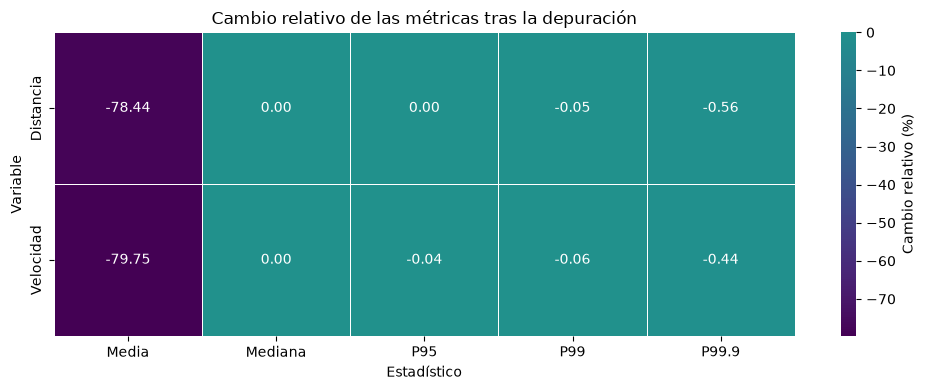

In [39]:
# ============================================================
# MAPA DE CAMBIOS RELATIVOS
# ============================================================
fig, ax = plt.subplots(figsize=(10, 4))

sns.heatmap(
    metric_change_pd, annot=True, fmt='.2f', center=0, cmap='viridis', linewidths=0.5,
    cbar_kws={'label': 'Cambio relativo (%)'}, ax=ax
)

ax.set_title('Cambio relativo de las métricas tras la depuración')
ax.set_xlabel('Estadístico')
ax.set_ylabel('Variable')

fig.tight_layout()

_ = save_figure(fig, '07_metric_change_comparison', images_dir)

plt.show()

#### Contraste entre métricas sensibles y estables

La comparación conjunta muestra dos comportamientos claramente diferenciados.

Las **medias** son las métricas más afectadas: la distancia media disminuye aproximadamente un **78,44 %** y la velocidad media un **79,75 %**.

En cambio, las medianas permanecen invariantes y las modificaciones de los percentiles elevados son muy reducidas. Incluso al alcanzar el percentil 99,9, el cambio continúa siendo inferior al **0,6 %**.

El contraste resume el efecto de la depuración: una fracción mínima de observaciones condicionaba intensamente determinadas medidas sensibles, mientras que la estructura representativa de ambas distribuciones permanecía prácticamente estable.

La depuración no transforma el comportamiento habitual del dataset; elimina la influencia estadística desproporcionada de su cola más extrema.

## 8. Resultados principales

La aplicación conjunta de los criterios seleccionados —**80 mph de velocidad máxima** y **50 millas de distancia máxima**— elimina únicamente **725 registros** de los **11.489.716 viajes** procesados, equivalentes al **0,0063 %** del dataset de referencia.

A pesar de esta proporción mínima, el efecto sobre las medias es muy elevado:

- la distancia media pasa de **14,07 a 3,03 millas**, una reducción aproximada del **78,44 %**;
- la velocidad media pasa de **63,17 a 12,79 mph**, una reducción aproximada del **79,75 %**.

La parte representativa de las distribuciones permanece, en cambio, prácticamente inalterada. Las medianas continúan en **1,83 millas** y **11,33 mph**, mientras que los percentiles 99 pasan únicamente de **18,41 a 18,40 millas** y de **36,18 a 36,16 mph**.

Esta estabilidad se mantiene incluso en el **percentil 99,9**: la distancia cambia de **23,30 a 23,17 millas** y la velocidad de **45,28 a 45,08 mph**. Considerando conjuntamente los perfiles P50, P95, P99 y P99,9 de ambas variables, la **variación relativa máxima es de aproximadamente 0,56 %**.

El análisis temporal confirma el mismo comportamiento. La proporción de registros eliminados se mantiene aproximadamente entre el **0,0051 % y el 0,0073 %** de los viajes diarios, pero determinadas medias estaban fuertemente condicionadas por valores extremos. El viernes constituye el ejemplo más acusado: la velocidad media pasa de **204,10 a 12,03 mph** y la distancia media de **37,61 a 3,01 millas**, mientras que sus medianas permanecen esencialmente invariantes.

La estructura territorial también se conserva. Los **15 distritos con mayor volumen de recogidas mantienen exactamente la misma posición** después de la depuración. Las diferencias porcentuales observadas son reducidas y no alteran la jerarquía espacial de la actividad.

El dataset resultante se persiste en formato **Parquet con compresión Snappy y particionado por día de la semana**. La relectura recupera los **11.488.991 registros y 23 columnas**, mantiene los tipos de datos y reproduce exactamente los recuentos diarios obtenidos desde el DataFrame depurado.

La validación integral confirma finalmente la conservación de registros, el cumplimiento de los límites establecidos, la estabilidad estadística, temporal y territorial, y la reproducibilidad del dataset persistido.

En conjunto, la depuración corrige una distorsión muy intensa de determinados estadísticos sensibles sin modificar de forma sustancial la estructura representativa del dataset.

In [40]:
# ============================================================
# RESUMEN FINAL DE RESULTADOS
# ============================================================
results_summary_pd = pd.DataFrame({
    'Indicador': [
        'Viajes de referencia',
        'Viajes depurados',
        'Registros eliminados',
        'Porcentaje eliminado',
        'Distancia media',
        'Velocidad media',
        'Distancia mediana',
        'Velocidad mediana',
        'P99 distancia',
        'P99 velocidad',
        'P99.9 distancia',
        'P99.9 velocidad',
        'Día con mayor volumen'
    ],
    'Referencia': [
        f'{trip_count:,}',
        '—',
        '—',
        '—',
        f"{comparison_stats_pd.loc['Referencia', 'avg_distance']:.2f} mi",
        f"{comparison_stats_pd.loc['Referencia', 'avg_speed']:.2f} mph",
        f"{comparison_stats_pd.loc['Referencia', 'median_distance']:.2f} mi",
        f"{comparison_stats_pd.loc['Referencia', 'median_speed']:.2f} mph",
        f"{comparison_stats_pd.loc['Referencia', 'p99_distance']:.2f} mi",
        f"{comparison_stats_pd.loc['Referencia', 'p99_speed']:.2f} mph",
        f"{p999_row['Distancia · referencia']:.2f} mi",
        f"{p999_row['Velocidad · referencia']:.2f} mph",
        reference_busiest_day
    ],
    'Depurado': [
        '—',
        f'{cleaned_trip_count:,}',
        f'{removed_trip_count:,}',
        f'{removed_pct:.4f} %',
        f"{comparison_stats_pd.loc['Depurado', 'avg_distance']:.2f} mi",
        f"{comparison_stats_pd.loc['Depurado', 'avg_speed']:.2f} mph",
        f"{comparison_stats_pd.loc['Depurado', 'median_distance']:.2f} mi",
        f"{comparison_stats_pd.loc['Depurado', 'median_speed']:.2f} mph",
        f"{comparison_stats_pd.loc['Depurado', 'p99_distance']:.2f} mi",
        f"{comparison_stats_pd.loc['Depurado', 'p99_speed']:.2f} mph",
        f"{p999_row['Distancia · depurado']:.2f} mi",
        f"{p999_row['Velocidad · depurado']:.2f} mph",
        cleaned_busiest_day
    ],
}).set_index('Indicador')

_ = save_table(results_summary_pd, '11_results_summary', tables_dir)

results_summary_pd

,Referencia,Depurado
Indicador,,
Viajes de referencia,"11,489,716",—
Viajes depurados,—,"11,488,991"
Registros eliminados,—,725
Porcentaje eliminado,—,0.0063 %
Distancia media,14.07 mi,3.03 mi
Velocidad media,63.17 mph,12.79 mph
Distancia mediana,1.83 mi,1.83 mi
Velocidad mediana,11.33 mph,11.33 mph
P99 distancia,18.41 mi,18.40 mi


### 8.1. Preparación del benchmark · Liberación de recursos persistidos

Antes de realizar la comparación final de rendimiento se liberan explícitamente los DataFrames persistidos mediante `unpersist()`.

Esta operación evita que el benchmark posterior pueda reutilizar inadvertidamente resultados almacenados en la caché de Spark. La comparación se realizará así sobre dos fuentes independientes: la reconstrucción del dataset depurado desde el CSV original y la lectura del dataset analítico previamente materializado en Parquet.

In [41]:
# ============================================================
# LIBERACIÓN DE DATAFRAMES PERSISTIDOS
# ============================================================
cached_dfs = {
    'nyc_trips_df': nyc_trips_df,
    'cleaned_trips_df': cleaned_trips_df,
    'district_quality_df': district_quality_df
}

cache_status_before = {
    name: df.is_cached for name, df in cached_dfs.items()
}

for df in cached_dfs.values():
    df.unpersist(blocking=True)

cache_status_after = {
    name: df.is_cached for name, df in cached_dfs.items()
}

assert not any(cache_status_after.values())

cache_release_pd = pd.DataFrame({
    'DataFrame': list(cached_dfs.keys()),
    'Antes': [
        'Cacheado' if cache_status_before[name] else 'No cacheado'
        for name in cached_dfs
    ],
    'Después': [
        'Cacheado' if cache_status_after[name] else 'Liberado'
        for name in cached_dfs
    ]
}).set_index('DataFrame')

cache_release_pd

,Antes,Después
DataFrame,,
nyc_trips_df,Cacheado,Liberado
cleaned_trips_df,Cacheado,Liberado
district_quality_df,Cacheado,Liberado


## 9. Rendimiento y reutilización del dataset analítico

La persistencia del dataset depurado permite evaluar una segunda ventaja del proceso de calidad de datos: su reutilización como capa analítica materializada.

Para realizar una comparación reproducible se contrastan dos rutas que conducen al mismo conjunto de **11.488.991 viajes**:

1. **CSV + pipeline**: lectura del CSV original, aplicación del esquema, creación de variables derivadas, filtros estructurales y criterios finales de depuración.
2. **Parquet analítico**: lectura directa del dataset depurado previamente materializado con compresión Snappy y particionado por día de la semana.

Ambas rutas se evalúan mediante la misma acción Spark (`count()`), sin utilizar persistencia explícita durante el benchmark.

Los tiempos deben interpretarse como **mediciones observadas en este entorno de ejecución**, no como una caracterización universal del rendimiento de CSV y Parquet. La mejora potencial tampoco se debe principalmente a la eliminación de 725 registros —solo el 0,0063 % del dataset—, sino a evitar la reconstrucción completa del pipeline y reutilizar una representación columnar, tipada y previamente transformada.

In [42]:
# ============================================================
# DATASET DEPURADO RECONSTRUIDO DESDE EL CSV ORIGINAL
# ============================================================
benchmark_csv_df = (
    spark
    .read
    .schema(TAXI_SCHEMA)
    .option('header', 'true')
    .csv(str(taxi_csv_path))

    # Duración del viaje en segundos
    .withColumn(
        'trip_duration_s',
        F.timestamp_diff('SECOND', F.col('tpep_pickup_datetime'), F.col('tpep_dropoff_datetime'))
    )
    # Filtros estructurales
    .filter(combined_filter)
    # Variables temporales
    .withColumn('pickup_hour', F.hour(F.col('tpep_pickup_datetime')))
    .withColumn('day_of_week', F.dayofweek(F.col('tpep_pickup_datetime')))
    # Día de la semana
    .withColumn(
        'day_of_week',
        F.when(F.col('day_of_week') == 2, 'lunes')
        .when(F.col('day_of_week') == 3, 'martes')
        .when(F.col('day_of_week') == 4, 'miercoles')
        .when(F.col('day_of_week') == 5, 'jueves')
        .when(F.col('day_of_week') == 6, 'viernes')
        .when(F.col('day_of_week') == 7, 'sabado')
        .otherwise('domingo')
    )

    # Velocidad media en millas por hora
    .withColumn(
        'speed',
        F.round(F.col('trip_distance') * 3600 / F.col('trip_duration_s'), 2)
    )
    # Criterios finales de depuración
    .filter((F.col('speed') <= SPEED_LIMIT) & (F.col('trip_distance') <= DISTANCE_LIMIT))
)


# ============================================================
# DATASET ANALÍTICO RELEÍDO DESDE PARQUET
# ============================================================
benchmark_parquet_df = (
    spark
    .read
    .parquet(str(cleaned_parquet_path))
)


# ============================================================
# COMPROBACIÓN PREVIA
# ============================================================
assert not benchmark_csv_df.is_cached
assert not benchmark_parquet_df.is_cached

print('Fuentes del benchmark preparadas sin persistencia explícita.')

Fuentes del benchmark preparadas sin persistencia explícita.


### 9.1. Benchmark de materialización

Para reducir el efecto de variaciones puntuales se realizan tres ejecuciones alternadas de la misma acción sobre ambas fuentes.

La mediana de los tiempos se utiliza como medida resumen. Esta estrategia no elimina completamente efectos externos, como la caché del sistema operativo o la actividad del equipo, pero proporciona una comparación más robusta que una única ejecución.

In [43]:
# ============================================================
# BENCHMARK ALTERNADO
# ============================================================
benchmark_repetitions = 3

csv_times = []
parquet_times = []

csv_count = None
parquet_count = None

for _ in range(benchmark_repetitions):
    # --------------------------------------------------------
    # CSV + reconstrucción completa del pipeline
    # --------------------------------------------------------
    start_time = perf_counter()

    csv_count = benchmark_csv_df.count()

    csv_times.append(perf_counter() - start_time)

    # --------------------------------------------------------
    # Parquet analítico materializado
    # --------------------------------------------------------
    start_time = perf_counter()

    parquet_count = benchmark_parquet_df.count()

    parquet_times.append(perf_counter() - start_time)


# ============================================================
# VALIDACIÓN
# ============================================================
assert csv_count == cleaned_trip_count
assert parquet_count == cleaned_trip_count
assert csv_count == parquet_count


# ============================================================
# RESULTADOS POR EJECUCIÓN
# ============================================================
benchmark_runs_pd = pd.DataFrame({
    'Ejecución': range(1, benchmark_repetitions + 1),
    'CSV + pipeline (s)': csv_times,
    'Parquet analítico (s)': parquet_times
}).set_index('Ejecución')

benchmark_runs_pd = benchmark_runs_pd.round(3)

_ = save_table(benchmark_runs_pd, '12_performance_benchmark_runs', tables_dir)

benchmark_runs_pd

,CSV + pipeline (s),Parquet analítico (s)
Ejecución,,
1,6.893,0.577
2,6.910,0.518
3,6.495,0.515


In [44]:
# ============================================================
# TIEMPOS MEDIANOS
# ============================================================
csv_median_seconds = float(pd.Series(csv_times).median())

parquet_median_seconds = float(pd.Series(parquet_times).median())


# ============================================================
# TAMAÑOS DE ALMACENAMIENTO
# ============================================================
csv_size_mb = taxi_csv_path.stat().st_size / 1024**2

storage_reduction_pct = (1 - parquet_size_mb / csv_size_mb) * 100

storage_factor = (csv_size_mb / parquet_size_mb)


# ============================================================
# DIFERENCIA DE RENDIMIENTO
# ============================================================
parquet_speedup = (csv_median_seconds / parquet_median_seconds)

time_reduction_pct = (1 - parquet_median_seconds / csv_median_seconds) * 100


# ============================================================
# RESUMEN
# ============================================================
performance_summary_pd = pd.DataFrame({
    'Indicador': [
        'Registros analizados',
        'Tamaño aproximado',
        'Tiempo mediano · 3 ejecuciones',
        'Reducción de almacenamiento',
        'Factor de reducción de tamaño',
        'Reducción del tiempo',
        'Factor de aceleración'
    ],
    'CSV + pipeline': [
        f'{csv_count:,}',
        f'{csv_size_mb:,.2f} MB',
        f'{csv_median_seconds:.2f} s',
        '—',
        '1.00×',
        '—',
        '1.00×'
    ],
    'Parquet analítico': [
        f'{parquet_count:,}',
        f'{parquet_size_mb:,.2f} MB',
        f'{parquet_median_seconds:.2f} s',
        f'{storage_reduction_pct:.2f} %',
        f'{storage_factor:.2f}×',
        f'{time_reduction_pct:.2f} %',
        f'{parquet_speedup:.2f}×'
    ]
}).set_index('Indicador')

_ = save_table(performance_summary_pd, '13_performance_benchmark_summary', tables_dir)

performance_summary_pd

,CSV + pipeline,Parquet analítico
Indicador,,
Registros analizados,"11,488,991","11,488,991"
Tamaño aproximado,"1,893.96 MB",363.22 MB
Tiempo mediano · 3 ejecuciones,6.89 s,0.52 s
Reducción de almacenamiento,—,80.82 %
Factor de reducción de tamaño,1.00×,5.21×
Reducción del tiempo,—,92.49 %
Factor de aceleración,1.00×,13.31×


### 9.2. Interpretación del benchmark

La comparación muestra una reducción notable del coste de reutilización del dataset una vez materializado como capa analítica.

La reconstrucción desde el CSV original —incluyendo lectura, aplicación del esquema, creación de variables derivadas, filtros estructurales y criterios de depuración— presenta un tiempo mediano de **6,89 s** en las tres ejecuciones realizadas. La lectura directa del dataset analítico en Parquet reduce ese tiempo a aproximadamente **0,52 s**, lo que representa una reducción observada del **92,49 %** y un factor de aceleración aproximado de **13,31×** para esta operación.

La diferencia no puede atribuirse al número de registros eliminados durante la depuración, ya que solo se excluye el **0,0063 %** de los viajes. La mejora procede principalmente de reutilizar una representación **columnar, comprimida, tipada y previamente transformada**, evitando reconstruir el pipeline completo desde el CSV original.

También se observa una reducción importante del almacenamiento: el fichero CSV de aproximadamente **1,89 GB** se transforma en una capa analítica Parquet de aproximadamente **363 MB**, una reducción cercana al **80,82 %**.

Estos valores corresponden al entorno y a las ejecuciones realizadas y deben interpretarse como evidencia experimental del proyecto, no como una estimación general del rendimiento de CSV frente a Parquet en cualquier infraestructura.

## 10. Conclusiones

Este notebook extiende el pipeline distribuido de referencia mediante una fase específica de **calidad de datos y depuración de valores extremos** aplicada a los viajes de taxi amarillo de Nueva York de enero de 2015.

El diagnóstico inicial identifica una separación muy acusada entre el comportamiento habitual de las variables y un conjunto extraordinariamente reducido de observaciones extremas. La comparación de distintos límites permite seleccionar criterios conservadores de **80 mph para la velocidad media del trayecto** y **50 millas para la distancia recorrida**.

La aplicación conjunta de ambos criterios elimina únicamente **725 viajes**, equivalentes al **0,0063 %** de los 11,49 millones de registros procesados. Sin embargo, esta modificación reduce aproximadamente un **78,44 %** la distancia media y un **79,75 %** la velocidad media.

La magnitud de esta corrección contrasta con la estabilidad del resto de la distribución. Las medianas permanecen invariantes y los perfiles de percentiles hasta **P99,9** apenas se modifican. La variación relativa máxima observada entre P50, P95, P99 y P99,9 es de aproximadamente **0,56 %**, lo que indica que la depuración actúa fundamentalmente sobre observaciones situadas mucho más allá de la cola representativa de las distribuciones.

El análisis temporal conduce a la misma conclusión. Los registros eliminados representan una proporción mínima durante todos los días de la semana y el sábado continúa siendo el día de mayor actividad. Las importantes correcciones observadas en determinadas medias diarias no se acompañan de desplazamientos equivalentes en las medianas.

La comparación territorial aporta una evidencia independiente: los **15 distritos con mayor volumen de recogidas conservan exactamente su posición** después de la depuración. De este modo, la corrección de los extremos tampoco modifica la estructura espacial principal de la actividad analizada.

El resultado depurado no se limita a una representación temporal dentro del notebook. Se persiste como dataset **Parquet particionado y comprimido**, se relee posteriormente y se valida tanto estructural como analíticamente. Los recuentos diarios obtenidos a partir del fichero persistido coinciden exactamente con los calculados desde el DataFrame depurado, proporcionando una comprobación adicional de integridad y reproducibilidad.

La materialización proporciona además una ventaja operativa medible. En el benchmark realizado sobre el mismo conjunto de 11.488.991 viajes, reconstruir el dataset depurado desde el CSV original requiere una mediana de **6,89 s**, mientras que reutilizar directamente la capa analítica Parquet requiere aproximadamente **0,52 s**. En este entorno se observa así una reducción del tiempo del **92,49 %** y una aceleración aproximada de **13,31×**, junto con una reducción del almacenamiento cercana al **80,82 %**.

Los dos datasets cumplen, por tanto, funciones diferentes dentro del proyecto. El **dataset procesado de referencia** preserva la implementación de partida y permite reproducir el análisis original, mientras que el **dataset depurado** constituye una base más adecuada para análisis sensibles a valores extremos.

Los límites utilizados deben interpretarse como **decisiones analíticas de depuración** y no como una demostración de que cada registro excluido sea necesariamente erróneo de forma individual. Las conclusiones corresponden al dataset y al periodo estudiados y no implican que los mismos criterios deban trasladarse automáticamente a otros periodos o fuentes.

En conjunto, el trabajo demuestra que una etapa explícita de calidad de datos puede corregir distorsiones estadísticas muy importantes conservando simultáneamente la distribución central, la cola alta representativa, los patrones temporales y la estructura territorial, y produciendo además un resultado persistente y reproducible para análisis posteriores.